In [1]:

import os

print(os.listdir("../data/data/raw/apnea-ecg"))

['a01.apn', 'a01.dat', 'a01.hea', 'a01.qrs', 'a02.apn', 'a02.dat', 'a02.hea', 'a03.apn', 'a03.dat', 'a03.hea', 'a04.apn', 'a04.dat', 'a04.hea', 'a05.apn', 'a05.dat', 'a05.hea', 'a06.apn', 'a06.dat', 'a06.hea', 'a07.apn', 'a07.dat', 'a07.hea', 'a08.apn', 'a08.dat', 'a08.hea', 'a09.apn', 'a09.dat', 'a09.hea', 'a10.apn', 'a10.dat', 'a10.hea', 'a11.apn', 'a11.dat', 'a11.hea', 'a12.apn', 'a12.dat', 'a12.hea', 'a13.apn', 'a13.dat', 'a13.hea', 'a14.apn', 'a14.dat', 'a14.hea', 'a15.apn', 'a15.dat', 'a15.hea', 'a16.apn', 'a16.dat', 'a16.hea', 'a17.apn', 'a17.dat', 'a17.hea', 'a18.apn', 'a18.dat', 'a18.hea', 'a19.apn', 'a19.dat', 'a19.hea', 'a20.apn', 'a20.dat', 'a20.hea', 'b01.apn', 'b01.dat', 'b01.hea', 'b02.dat', 'b02.hea', 'b03.apn', 'b03.dat', 'b03.hea', 'b04.apn', 'b04.dat', 'b04.hea', 'b05.apn', 'b05.dat', 'b05.hea', 'c01.apn', 'c01.dat', 'c01.hea', 'c02.apn', 'c02.dat', 'c02.hea', 'c03.apn', 'c03.dat', 'c03.hea', 'c04.apn', 'c04.dat', 'c04.hea', 'c05.apn', 'c05.dat', 'c05.hea', 'c06.apn'

In [2]:
%pip install numpy pandas matplotlib scikit-learn wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully")

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Libraries imported successfully


In [3]:
import wfdb

record = wfdb.rdrecord("../data/data/raw/apnea-ecg/a01")

print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)

Signal shape: (2957000, 1)
Sampling frequency: 100
Channels: ['ECG']


In [4]:
ecg = record.p_signal[:, 0]

print("ECG shape:", ecg.shape)
print("First 10 samples:")
print(ecg[:10])

ECG shape: (2957000,)
First 10 samples:
[-0.06  -0.065 -0.06  -0.075 -0.065 -0.07  -0.07  -0.09  -0.08  -0.095]


In [5]:
from pathlib import Path
import wfdb
import numpy as np

DATA_DIR = Path("../data/data/raw/apnea-ecg")

print("ECG folder exists:", DATA_DIR.exists())

ECG folder exists: True


In [6]:
# Check ECG sampling frequency and annotation alignment

print("Sampling frequency:", record.fs)
print("ECG duration (minutes):",
      len(record.p_signal) / record.fs / 60)

ann = wfdb.rdann(str(DATA_DIR / "a01"), "apn")

print("\nFirst 15 annotation symbols:")
print(ann.symbol[:15])

print("\nFirst 15 annotation times (seconds):")
print(ann.sample[:15] / record.fs)

print("\nDifferences between annotation times (seconds):")
print(np.diff(ann.sample[:15]) / record.fs)

print("\nUnique annotation symbols and counts:")
print(np.unique(ann.symbol, return_counts=True))

Sampling frequency: 100
ECG duration (minutes): 492.8333333333333

First 15 annotation symbols:
['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'A']

First 15 annotation times (seconds):
[  0.  60. 120. 180. 240. 300. 360. 420. 480. 540. 600. 660. 720. 780.
 840.]

Differences between annotation times (seconds):
[60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60.]

Unique annotation symbols and counts:
(array(['A', 'N'], dtype='<U1'), array([470,  19]))


In [7]:
fs = record.fs

print("Sampling frequency:", fs)

Sampling frequency: 100


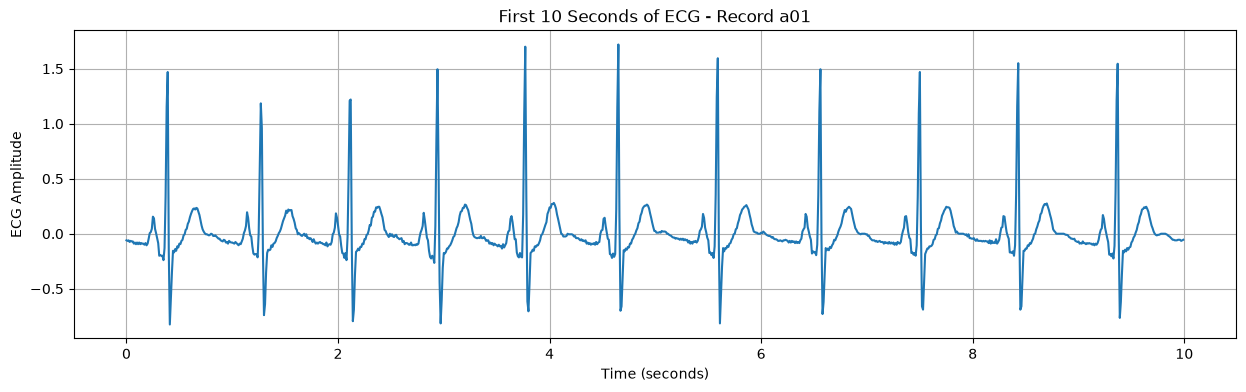

In [8]:
seconds = 10

samples = int(seconds * fs)

plt.figure(figsize=(15, 4))

plt.plot(
    np.arange(samples) / fs,
    ecg[:samples]
)

plt.xlabel("Time (seconds)")
plt.ylabel("ECG Amplitude")
plt.title("First 10 Seconds of ECG - Record a01")
plt.grid()

plt.show()

In [9]:

import wfdb

annotation = wfdb.rdann("../data/data/raw/apnea-ecg/a01", "apn")

print("Number of annotations:", len(annotation.sample))

print("First 20 annotation samples:")
print(annotation.sample[:20])

print("First 20 symbols:")
print(annotation.symbol[:20])


Number of annotations: 489
First 20 annotation samples:
[     0   6000  12000  18000  24000  30000  36000  42000  48000  54000
  60000  66000  72000  78000  84000  90000  96000 102000 108000 114000]
First 20 symbols:
['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'A', 'A', 'A', 'A', 'A', 'A']


In [10]:
print("Sampling frequency:", record.fs)

print("\nFirst 20 annotation samples:")
print(annotation.sample[:20])

print("\nFirst 20 annotation times (seconds):")
print(annotation.sample[:20] / record.fs)

print("\nFirst 20 annotation symbols:")
print(annotation.symbol[:20])

Sampling frequency: 100

First 20 annotation samples:
[     0   6000  12000  18000  24000  30000  36000  42000  48000  54000
  60000  66000  72000  78000  84000  90000  96000 102000 108000 114000]

First 20 annotation times (seconds):
[   0.   60.  120.  180.  240.  300.  360.  420.  480.  540.  600.  660.
  720.  780.  840.  900.  960. 1020. 1080. 1140.]

First 20 annotation symbols:
['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'A', 'A', 'A', 'A', 'A', 'A']


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ECG signal already loaded in 'record'
ecg = record.p_signal[:, 0]
fs = record.fs

print("Sampling frequency:", fs)
print("Number of samples:", len(ecg))

# Remove DC offset
ecg_centered = ecg - np.mean(ecg)

print("Original mean:", np.mean(ecg))
print("Mean after centering:", np.mean(ecg_centered))

Sampling frequency: 100
Number of samples: 2957000
Original mean: 0.0005639279675346633
Mean after centering: -1.275949248186044e-18


In [12]:
# Moving average window
window_seconds = 0.8
window = int(window_seconds * fs)

# Make sure window is odd
if window % 2 == 0:
    window += 1

# Estimate baseline
baseline = np.convolve(
    ecg_centered,
    np.ones(window) / window,
    mode='same'
)

# Remove baseline
ecg_detrended = ecg_centered - baseline

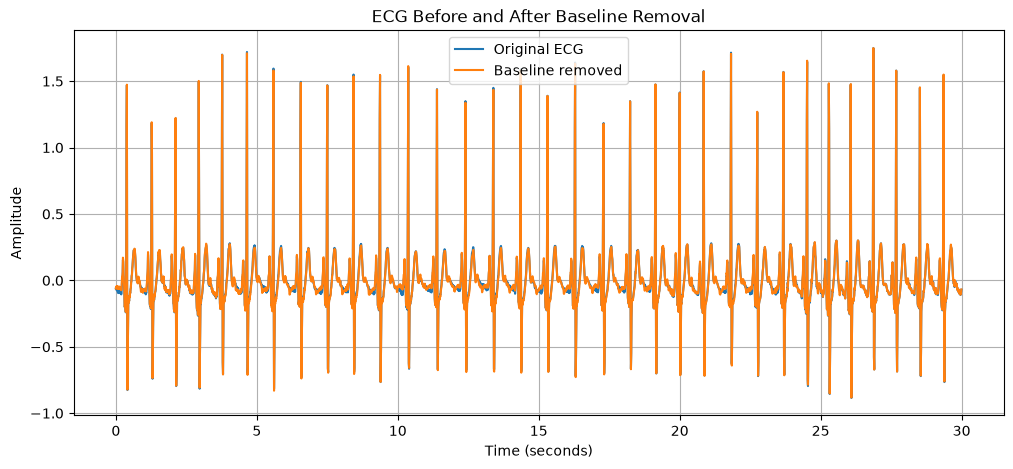

In [13]:
duration = 30
samples = int(duration * fs)

time = np.arange(samples) / fs

plt.figure(figsize=(12, 5))

plt.plot(time, ecg_centered[:samples], label="Original ECG")
plt.plot(time, ecg_detrended[:samples], label="Baseline removed")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("ECG Before and After Baseline Removal")
plt.legend()
plt.grid()
plt.show()

In [14]:
# Low-pass moving average
lp_window_seconds = 0.08
lp_window = int(lp_window_seconds * fs)

if lp_window < 1:
    lp_window = 1

ecg_filtered = np.convolve(
    ecg_detrended,
    np.ones(lp_window) / lp_window,
    mode='same'
)

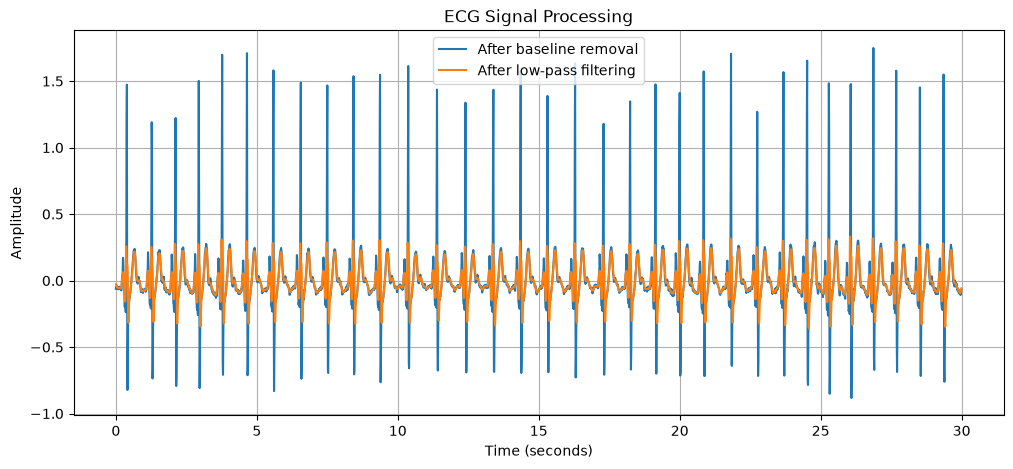

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(time, ecg_detrended[:samples], label="After baseline removal")
plt.plot(time, ecg_filtered[:samples], label="After low-pass filtering")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("ECG Signal Processing")
plt.legend()
plt.grid()
plt.show()

In [16]:
# R-peak detection using threshold + minimum distance

from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# Use the filtered ECG
signal = ecg_filtered

# Minimum distance between two heartbeats
# At least 0.5 seconds apart -> maximum ~120 BPM
min_distance = int(0.5 * fs)

# Set threshold based on the signal
threshold = np.mean(signal) + 0.5 * np.std(signal)

# Detect peaks
peaks, properties = find_peaks(
    signal,
    height=threshold,
    distance=min_distance
)

print("Number of detected R-peaks:", len(peaks))
print("First 20 R-peak samples:")
print(peaks[:20])

print("\nFirst 20 R-peak times (seconds):")
print(peaks[:20] / fs)

Number of detected R-peaks: 29820
First 20 R-peak samples:
[  37  126  210  292  375  463  557  654  748  841  935 1035 1137 1238
 1337 1434 1529 1627 1728 1822]

First 20 R-peak times (seconds):
[ 0.37  1.26  2.1   2.92  3.75  4.63  5.57  6.54  7.48  8.41  9.35 10.35
 11.37 12.38 13.37 14.34 15.29 16.27 17.28 18.22]


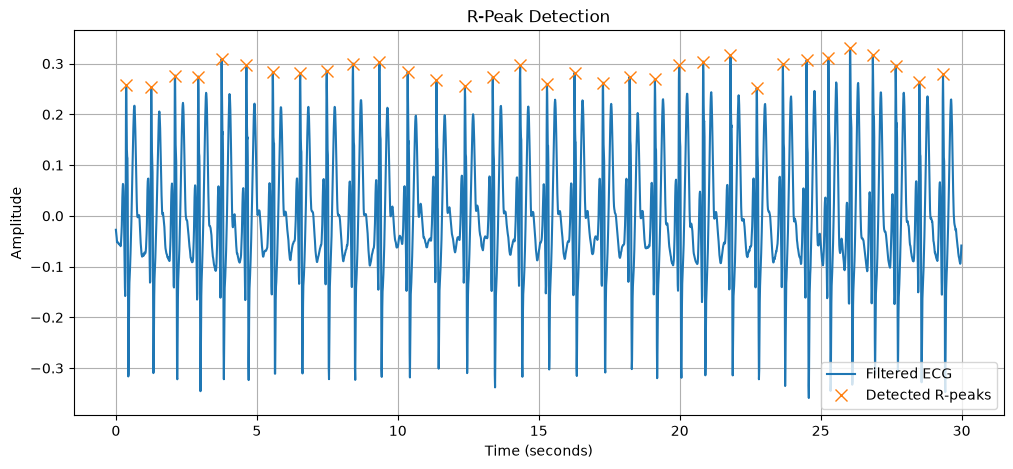

In [17]:
# Plot detected R-peaks over ECG

duration = 30
samples = int(duration * fs)

time = np.arange(samples) / fs

plt.figure(figsize=(12, 5))

plt.plot(time, signal[:samples], label="Filtered ECG")

# Only peaks within first 30 seconds
visible_peaks = peaks[peaks < samples]

plt.plot(
    visible_peaks / fs,
    signal[visible_peaks],
    "x",
    markersize=8,
    label="Detected R-peaks"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("R-Peak Detection")
plt.legend()
plt.grid()
plt.show()

In [18]:
# Calculate RR intervals

rr_intervals = np.diff(peaks) / fs

print("Number of RR intervals:", len(rr_intervals))

print("\nFirst 20 RR intervals (seconds):")
print(rr_intervals[:20])

Number of RR intervals: 29819

First 20 RR intervals (seconds):
[0.89 0.84 0.82 0.83 0.88 0.94 0.97 0.94 0.93 0.94 1.   1.02 1.01 0.99
 0.97 0.95 0.98 1.01 0.94 0.9 ]


In [19]:
# Calculate instantaneous heart rate

heart_rate = 60 / rr_intervals

print("First 20 heart-rate values:")
print(heart_rate[:20], "BPM")

First 20 heart-rate values:
[67.41573034 71.42857143 73.17073171 72.28915663 68.18181818 63.82978723
 61.8556701  63.82978723 64.51612903 63.82978723 60.         58.82352941
 59.40594059 60.60606061 61.8556701  63.15789474 61.2244898  59.40594059
 63.82978723 66.66666667] BPM


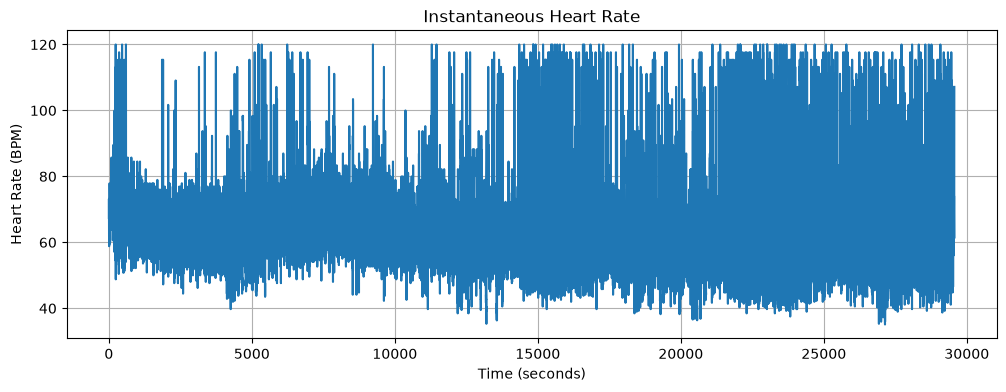

In [20]:
# Time corresponding to each RR interval
rr_time = peaks[1:] / fs

plt.figure(figsize=(12, 4))

plt.plot(rr_time, heart_rate)

plt.xlabel("Time (seconds)")
plt.ylabel("Heart Rate (BPM)")
plt.title("Instantaneous Heart Rate")
plt.grid()
plt.show()

In [21]:
# Step 1: Get the timestamp of each RR interval
rr_time = peaks[1:] / fs

# Step 2: Get annotation timestamps and labels
ann_time = annotation.sample / fs
ann_labels = np.array(annotation.symbol)


# Step 3: Find the annotation corresponding to each RR midpoint
rr_mid_time = (peaks[:-1] + peaks[1:]) / (2 * fs)

# Find the most recent annotation timestamp at or before each midpoint
minute_idx = np.searchsorted(ann_time, rr_mid_time, side="right") - 1

# Keep only RR intervals within the annotation time range
valid = (
    (minute_idx >= 0) &
    (minute_idx < len(ann_labels)) &
    (rr_mid_time < len(record.p_signal) / fs)
)

# Step 4: Create the labeled RR dataset
rr_labeled = pd.DataFrame({
    "time_sec": rr_mid_time[valid],
    "rr_interval_sec": rr_intervals[valid],
    "heart_rate_bpm": heart_rate[valid],
    "minute": minute_idx[valid],
    "label": ann_labels[minute_idx[valid]]
})

# Keep only the expected classes
rr_labeled = rr_labeled[
    rr_labeled["label"].isin(["A", "N"])
].reset_index(drop=True)

print("First 10 labeled RR intervals:")
display(rr_labeled.head(10))

print("\nDataset shape:", rr_labeled.shape)
print("\nLabel counts:")
print(rr_labeled["label"].value_counts())

print("\nLabel proportions:")
print(rr_labeled["label"].value_counts(normalize=True))


First 10 labeled RR intervals:


,time_sec,rr_interval_sec,heart_rate_bpm,minute,label
0,0.815,0.89,67.415730,0,N
1,1.680,0.84,71.428571,0,N
2,2.510,0.82,73.170732,0,N
3,3.335,0.83,72.289157,0,N
4,4.190,0.88,68.181818,0,N
5,5.100,0.94,63.829787,0,N
6,6.055,0.97,61.855670,0,N
7,7.010,0.94,63.829787,0,N
8,7.945,0.93,64.516129,0,N
9,8.880,0.94,63.829787,0,N



Dataset shape: (29819, 5)

Label counts:
label
A    28508
N     1311
Name: count, dtype: int64

Label proportions:
label
A    0.956035
N    0.043965
Name: proportion, dtype: float64


In [22]:
from pathlib import Path
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

# Path relative to your notebooks folder
DATA_DIR = Path("../data/data/raw/apnea-ecg")

# List the patient IDs you downloaded.
# Example assumes you downloaded a01 through a15.

patient_ids = (
    [f"a{i:02d}" for i in range(1, 21)] +
    [f"b{i:02d}" for i in range(1, 6)] +
    [f"c{i:02d}" for i in range(1, 11)]
)

print("Total patients:", len(patient_ids))
print(patient_ids)

for patient in patient_ids:
    base = DATA_DIR / patient

    print(
        patient,
        "ECG:", base.with_suffix(".dat").exists(),
        "Header:", base.with_suffix(".hea").exists(),
        "Annotations:", base.with_suffix(".apn").exists()
    )

Total patients: 35
['a01', 'a02', 'a03', 'a04', 'a05', 'a06', 'a07', 'a08', 'a09', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a16', 'a17', 'a18', 'a19', 'a20', 'b01', 'b02', 'b03', 'b04', 'b05', 'c01', 'c02', 'c03', 'c04', 'c05', 'c06', 'c07', 'c08', 'c09', 'c10']
a01 ECG: True Header: True Annotations: True
a02 ECG: True Header: True Annotations: True
a03 ECG: True Header: True Annotations: True
a04 ECG: True Header: True Annotations: True
a05 ECG: True Header: True Annotations: True
a06 ECG: True Header: True Annotations: True
a07 ECG: True Header: True Annotations: True
a08 ECG: True Header: True Annotations: True
a09 ECG: True Header: True Annotations: True
a10 ECG: True Header: True Annotations: True
a11 ECG: True Header: True Annotations: True
a12 ECG: True Header: True Annotations: True
a13 ECG: True Header: True Annotations: True
a14 ECG: True Header: True Annotations: True
a15 ECG: True Header: True Annotations: True
a16 ECG: True Header: True Annotations: True
a17 ECG: True H

In [23]:
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
from pathlib import Path

WINDOW_SECONDS = 60
TARGET_FS = 100
WINDOW_SAMPLES = WINDOW_SECONDS * TARGET_FS

# Bandpass filter: 0.5–40 Hz
sos = butter(
    4, [0.5, 40],
    btype="bandpass",
    fs=TARGET_FS,
    output="sos"
)

X_list = []
y_list = []
groups = []
segment_info = []
failed_patients = []

for patient in patient_ids:
    base = DATA_DIR / patient
    print(f"\nProcessing {patient}...")

    # Check that all required files exist
    if not all(
        base.with_suffix(ext).exists()
        for ext in [".dat", ".hea", ".apn"]
    ):
        print(f"Skipping {patient}: required file missing")
        failed_patients.append(patient)
        continue

    # Load the recording and annotations safely
    try:
        record = wfdb.rdrecord(str(base))
        annotation = wfdb.rdann(str(base), "apn")

    except Exception as e:
        print(f"Skipping {patient}: could not load recording")
        print(f"Reason: {type(e).__name__}: {e}")
        failed_patients.append(patient)
        continue

    try:
        ecg = record.p_signal[:, 0]
        fs = record.fs

        if not np.isclose(fs, TARGET_FS):
            print(f"Skipping {patient}: sampling rate is {fs} Hz")
            failed_patients.append(patient)
            continue

        # Filter ECG
        ecg_filtered = sosfiltfilt(sos, ecg)

        labels = np.asarray(annotation.symbol)

        # Use only complete minutes with corresponding annotations
        n_segments = min(
            len(ecg_filtered) // WINDOW_SAMPLES,
            len(labels)
        )

        patient_count = 0

        for minute in range(n_segments):
            label = labels[minute]

            if label not in ["A", "N"]:
                continue

            start = minute * WINDOW_SAMPLES
            end = start + WINDOW_SAMPLES

            segment = ecg_filtered[start:end]

            # Normalize the segment
            segment = (segment - np.mean(segment)) / (
                np.std(segment) + 1e-8
            )

            X_list.append(segment.astype(np.float32))
            y_list.append(1 if label == "A" else 0)
            groups.append(patient)

            segment_info.append({
                "patient": patient,
                "minute": minute,
                "label": label
            })

            patient_count += 1

        print(f"{patient}: successfully added {patient_count} segments")

    except Exception as e:
        print(f"Error processing {patient}: {type(e).__name__}: {e}")
        failed_patients.append(patient)

# Convert collected data to arrays
if len(X_list) == 0:
    raise ValueError(
        "No segments were created. Check the recording and annotation files."
    )

X = np.asarray(X_list, dtype=np.float32)[..., np.newaxis]
y = np.asarray(y_list, dtype=np.int32)
groups = np.asarray(groups)
metadata = pd.DataFrame(segment_info)

print("\n========== DATASET SUMMARY ==========")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Patients successfully used:", np.unique(groups))
print("Number of patients used:", len(np.unique(groups)))
print("Failed patients:", sorted(set(failed_patients)))

print("\nLabel counts:")
print(
    pd.Series(y)
    .map({0: "Normal", 1: "Apnea"})
    .value_counts()
)


Processing a01...
a01: successfully added 489 segments

Processing a02...
Skipping a02: could not load recording
Reason: ValueError: Samples were not loaded correctly

Processing a03...
a03: successfully added 519 segments

Processing a04...
a04: successfully added 492 segments

Processing a05...
a05: successfully added 453 segments

Processing a06...
a06: successfully added 509 segments

Processing a07...
a07: successfully added 510 segments

Processing a08...
a08: successfully added 500 segments

Processing a09...
a09: successfully added 495 segments

Processing a10...
a10: successfully added 516 segments

Processing a11...
a11: successfully added 466 segments

Processing a12...
a12: successfully added 577 segments

Processing a13...
a13: successfully added 494 segments

Processing a14...
a14: successfully added 509 segments

Processing a15...
a15: successfully added 509 segments

Processing a16...
a16: successfully added 481 segments

Processing a17...
a17: successfully added 484 s

In [24]:
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
from pathlib import Path

WINDOW_SECONDS = 60
TARGET_FS = 100
WINDOW_SAMPLES = WINDOW_SECONDS * TARGET_FS

# Bandpass filter: 0.5–40 Hz
sos = butter(
    4, [0.5, 40],
    btype="bandpass",
    fs=TARGET_FS,
    output="sos"
)

X_list = []
y_list = []
groups = []
segment_info = []
failed_patients = []

for patient in patient_ids:
    base = DATA_DIR / patient
    print(f"\nProcessing {patient}...")

    # Check that all required files exist
    if not all(
        base.with_suffix(ext).exists()
        for ext in [".dat", ".hea", ".apn"]
    ):
        print(f"Skipping {patient}: required file missing")
        failed_patients.append(patient)
        continue

    # Load the recording and annotations safely
    try:
        record = wfdb.rdrecord(str(base))
        annotation = wfdb.rdann(str(base), "apn")

    except Exception as e:
        print(f"Skipping {patient}: could not load recording")
        print(f"Reason: {type(e).__name__}: {e}")
        failed_patients.append(patient)
        continue

    try:
        ecg = record.p_signal[:, 0]
        fs = record.fs

        if not np.isclose(fs, TARGET_FS):
            print(f"Skipping {patient}: sampling rate is {fs} Hz")
            failed_patients.append(patient)
            continue

        # Filter ECG
        ecg_filtered = sosfiltfilt(sos, ecg)

        labels = np.asarray(annotation.symbol)

        # Use only complete minutes with corresponding annotations
        n_segments = min(
            len(ecg_filtered) // WINDOW_SAMPLES,
            len(labels)
        )

        patient_count = 0

        for minute in range(n_segments):
            label = labels[minute]

            if label not in ["A", "N"]:
                continue

            start = minute * WINDOW_SAMPLES
            end = start + WINDOW_SAMPLES

            segment = ecg_filtered[start:end]

            # Normalize the segment
            segment = (segment - np.mean(segment)) / (
                np.std(segment) + 1e-8
            )

            X_list.append(segment.astype(np.float32))
            y_list.append(1 if label == "A" else 0)
            groups.append(patient)

            segment_info.append({
                "patient": patient,
                "minute": minute,
                "label": label
            })

            patient_count += 1

        print(f"{patient}: successfully added {patient_count} segments")

    except Exception as e:
        print(f"Error processing {patient}: {type(e).__name__}: {e}")
        failed_patients.append(patient)

# Convert collected data to arrays
if len(X_list) == 0:
    raise ValueError(
        "No segments were created. Check the recording and annotation files."
    )

X = np.asarray(X_list, dtype=np.float32)[..., np.newaxis]
y = np.asarray(y_list, dtype=np.int32)
groups = np.asarray(groups)
metadata = pd.DataFrame(segment_info)

print("\n========== DATASET SUMMARY ==========")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Patients successfully used:", np.unique(groups))
print("Number of patients used:", len(np.unique(groups)))
print("Failed patients:", sorted(set(failed_patients)))

print("\nLabel counts:")
print(
    pd.Series(y)
    .map({0: "Normal", 1: "Apnea"})
    .value_counts()
)


Processing a01...
a01: successfully added 489 segments

Processing a02...
Skipping a02: could not load recording
Reason: ValueError: Samples were not loaded correctly

Processing a03...
a03: successfully added 519 segments

Processing a04...
a04: successfully added 492 segments

Processing a05...
a05: successfully added 453 segments

Processing a06...
a06: successfully added 509 segments

Processing a07...
a07: successfully added 510 segments

Processing a08...
a08: successfully added 500 segments

Processing a09...
a09: successfully added 495 segments

Processing a10...
a10: successfully added 516 segments

Processing a11...
a11: successfully added 466 segments

Processing a12...
a12: successfully added 577 segments

Processing a13...
a13: successfully added 494 segments

Processing a14...
a14: successfully added 509 segments

Processing a15...
a15: successfully added 509 segments

Processing a16...
a16: successfully added 481 segments

Processing a17...
a17: successfully added 484 s

In [25]:
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
from pathlib import Path

WINDOW_SECONDS = 60
TARGET_FS = 100
WINDOW_SAMPLES = WINDOW_SECONDS * TARGET_FS

# Bandpass filter: 0.5–40 Hz
sos = butter(
    4, [0.5, 40],
    btype="bandpass",
    fs=TARGET_FS,
    output="sos"
)

X_list = []
y_list = []
groups = []
segment_info = []
failed_patients = []

for patient in patient_ids:
    base = DATA_DIR / patient
    print(f"\nProcessing {patient}...")

    # Check that all required files exist
    if not all(
        base.with_suffix(ext).exists()
        for ext in [".dat", ".hea", ".apn"]
    ):
        print(f"Skipping {patient}: required file missing")
        failed_patients.append(patient)
        continue

    # Load the recording and annotations safely
    try:
        record = wfdb.rdrecord(str(base))
        annotation = wfdb.rdann(str(base), "apn")

    except Exception as e:
        print(f"Skipping {patient}: could not load recording")
        print(f"Reason: {type(e).__name__}: {e}")
        failed_patients.append(patient)
        continue

    try:
        ecg = record.p_signal[:, 0]
        fs = record.fs

        if not np.isclose(fs, TARGET_FS):
            print(f"Skipping {patient}: sampling rate is {fs} Hz")
            failed_patients.append(patient)
            continue

        # Filter ECG
        ecg_filtered = sosfiltfilt(sos, ecg)

        labels = np.asarray(annotation.symbol)

        # Use only complete minutes with corresponding annotations
        n_segments = min(
            len(ecg_filtered) // WINDOW_SAMPLES,
            len(labels)
        )

        patient_count = 0

        for minute in range(n_segments):
            label = labels[minute]

            if label not in ["A", "N"]:
                continue

            start = minute * WINDOW_SAMPLES
            end = start + WINDOW_SAMPLES

            segment = ecg_filtered[start:end]

            # Normalize the segment
            segment = (segment - np.mean(segment)) / (
                np.std(segment) + 1e-8
            )

            X_list.append(segment.astype(np.float32))
            y_list.append(1 if label == "A" else 0)
            groups.append(patient)

            segment_info.append({
                "patient": patient,
                "minute": minute,
                "label": label
            })

            patient_count += 1

        print(f"{patient}: successfully added {patient_count} segments")

    except Exception as e:
        print(f"Error processing {patient}: {type(e).__name__}: {e}")
        failed_patients.append(patient)

# Convert collected data to arrays
if len(X_list) == 0:
    raise ValueError(
        "No segments were created. Check the recording and annotation files."
    )

# Convert collected data to full dataset arrays
X_all = np.asarray(X_list, dtype=np.float32)[..., np.newaxis]
y_all = np.asarray(y_list, dtype=np.int32)
groups_all = np.asarray(groups)
metadata_all = pd.DataFrame(segment_info)

print("\n========== DATASET SUMMARY ==========")
print("X_all shape:", X_all.shape)
print("y_all shape:", y_all.shape)
print("groups_all shape:", groups_all.shape)
print("metadata_all shape:", metadata_all.shape)

print("\nPatients successfully used:")
print(sorted(np.unique(groups_all)))

print("\nNumber of patients:", len(np.unique(groups_all)))
print("Failed patients:", sorted(set(failed_patients)))

print("\nLabel counts:")
print(pd.Series(y_all).map({
    0: "Normal",
    1: "Apnea"
}).value_counts())

# Verify that every ECG window has matching information
assert len(X_all) == len(y_all) == len(groups_all) == len(metadata_all)

# Verify that numerical labels match metadata labels
metadata_numeric = metadata_all["label"].map({
    "N": 0,
    "A": 1
}).to_numpy()

assert np.array_equal(metadata_numeric, y_all)

print("\nAll dataset alignment checks passed!")


Processing a01...
a01: successfully added 489 segments

Processing a02...
Skipping a02: could not load recording
Reason: ValueError: Samples were not loaded correctly

Processing a03...
a03: successfully added 519 segments

Processing a04...
a04: successfully added 492 segments

Processing a05...
a05: successfully added 453 segments

Processing a06...
a06: successfully added 509 segments

Processing a07...
a07: successfully added 510 segments

Processing a08...
a08: successfully added 500 segments

Processing a09...
a09: successfully added 495 segments

Processing a10...
a10: successfully added 516 segments

Processing a11...
a11: successfully added 466 segments

Processing a12...
a12: successfully added 577 segments

Processing a13...
a13: successfully added 494 segments

Processing a14...
a14: successfully added 509 segments

Processing a15...
a15: successfully added 509 segments

Processing a16...
a16: successfully added 481 segments

Processing a17...
a17: successfully added 484 s

In [26]:
# Verify labels assigned to ECG windows

print("Total windows:", len(y))
print("Window shape:", X.shape)

print("\nLabel counts:")
print(pd.Series(y).map({
    0: "Normal",
    1: "Apnea"
}).value_counts())

print("\nWindows per patient and label:")
display(pd.crosstab(
    metadata["patient"],
    metadata["label"]
))

print("\nFirst 15 window labels:")
display(metadata.head(15))

Total windows: 15978
Window shape: (15978, 6000, 1)

Label counts:
Normal    9980
Apnea     5998
Name: count, dtype: int64

Windows per patient and label:


label,A,N
patient,,
a01,470,19
a03,246,273
a04,453,39
a05,276,177
a06,206,303
a07,321,189
a08,189,311
a09,381,114
a10,99,417



First 15 window labels:


,patient,minute,label
0,a01,0,N
1,a01,1,N
2,a01,2,N
3,a01,3,N
4,a01,4,N
5,a01,5,N
6,a01,6,N
7,a01,7,N
8,a01,8,N
9,a01,9,N


In [27]:
# Compare RR features between normal and apnea intervals

print("Feature statistics by class:")
display(
    rr_labeled.groupby("label")[
        ["rr_interval_sec", "heart_rate_bpm"]
    ].agg(["count", "mean", "std", "median"])
)

print("\nChecking for invalid values:")
print(
    rr_labeled[
        ["rr_interval_sec", "heart_rate_bpm"]
    ].isna().sum()
)

print("\nChecking for infinite values:")
print(
    np.isinf(
        rr_labeled[["rr_interval_sec", "heart_rate_bpm"]]
    ).sum()
)

Feature statistics by class:


rr_interval_sec                            heart_rate_bpm             \
                count      mean       std median          count       mean   
label                                                                        
A               28508  0.997033  0.178512   1.01          28508  62.392627   
N                1311  0.870122  0.150249   0.85           1311  71.014054   

                             
             std     median  
label                        
A      12.888976  59.405941  
N      12.373340  70.588235


Checking for invalid values:
rr_interval_sec    0
heart_rate_bpm     0
dtype: int64

Checking for infinite values:
rr_interval_sec    0
heart_rate_bpm     0
dtype: int64


Minutes containing multiple labels: 0


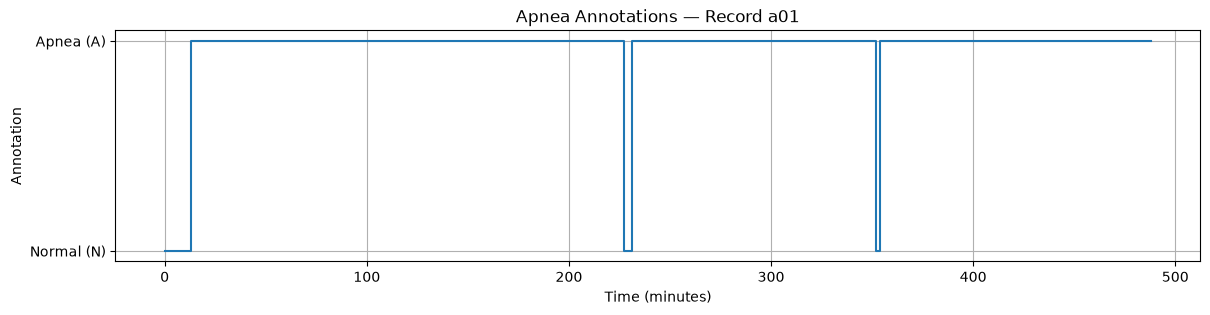

In [28]:
# Check that every minute has a single annotation label
minute_check = (
    rr_labeled.groupby("minute")["label"]
    .nunique()
)

print("Minutes containing multiple labels:",
      (minute_check > 1).sum())

# Plot annotation labels across time
plt.figure(figsize=(14, 3))

plt.step(
    ann_time / 60,
    np.where(ann_labels == "A", 1, 0),
    where="post"
)

plt.yticks([0, 1], ["Normal (N)", "Apnea (A)"])
plt.xlabel("Time (minutes)")
plt.ylabel("Annotation")
plt.title("Apnea Annotations — Record a01")
plt.grid()
plt.show()

In [29]:

from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# Experiment 1: New patient-wise split
# Approximately 60% train, 20% validation, 20% test

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=21
)

train_val_idx, test_idx = next(
    split1.split(X_all, y_all, groups=groups_all)
)

# Reserve 25% of remaining patients for validation
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=21
)

train_rel, val_rel = next(
    split2.split(
        X_all[train_val_idx],
        y_all[train_val_idx],
        groups=groups_all[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

# Create datasets
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

groups_train = groups_all[train_idx]
groups_val = groups_all[val_idx]
groups_test = groups_all[test_idx]

# Corresponding metadata
metadata_train = metadata_all.iloc[train_idx].reset_index(drop=True)
metadata_val = metadata_all.iloc[val_idx].reset_index(drop=True)
metadata_test = metadata_all.iloc[test_idx].reset_index(drop=True)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nPatients in each split:")
print("Train:", sorted(np.unique(groups_train)))
print("Validation:", sorted(np.unique(groups_val)))
print("Test:", sorted(np.unique(groups_test)))

# Confirm no patient overlap
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

# Confirm metadata alignment
assert len(metadata_train) == len(y_train)
assert len(metadata_val) == len(y_val)
assert len(metadata_test) == len(y_test)

print("\nPatient-level split verified.")


Training: (9294, 6000, 1) (9294,)
Validation: (3314, 6000, 1) (3314,)
Testing: (3370, 6000, 1) (3370,)

Patients in each split:
Train: [np.str_('a04'), np.str_('a06'), np.str_('a07'), np.str_('a08'), np.str_('a10'), np.str_('a12'), np.str_('a13'), np.str_('a14'), np.str_('a15'), np.str_('a16'), np.str_('a17'), np.str_('a18'), np.str_('a19'), np.str_('b03'), np.str_('b04'), np.str_('c01'), np.str_('c07'), np.str_('c08'), np.str_('c10')]
Validation: [np.str_('a05'), np.str_('a09'), np.str_('a11'), np.str_('c02'), np.str_('c05'), np.str_('c06'), np.str_('c09')]
Test: [np.str_('a01'), np.str_('a03'), np.str_('a20'), np.str_('b01'), np.str_('b05'), np.str_('c03'), np.str_('c04')]

Patient-level split verified.


In [30]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("metadata shape:", metadata.shape)

print("\nX_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nMetadata rows by patient:")
print(metadata.groupby("patient").size())

X shape: (15978, 6000, 1)
y shape: (15978,)
metadata shape: (15978, 3)

X_train: (9294, 6000, 1)
X_val: (3314, 6000, 1)
X_test: (3370, 6000, 1)

Metadata rows by patient:
patient
a01    489
a03    519
a04    492
a05    453
a06    509
a07    510
a08    500
a09    495
a10    516
a11    466
a12    577
a13    494
a14    509
a15    509
a16    481
a17    484
a18    489
a19    502
a20    510
b01    486
b03    440
b04    428
b05    432
c01    483
c02    501
c03    453
c04    481
c05    465
c06    467
c07    428
c08    513
c09    467
c10    430
dtype: int64


In [43]:
import numpy as np

# Common patients with SpO2
# Keep these assignments identical to the SpO2 split

train_patients = [
    'a01', 'c01', 'c02', 'c03',
    'a05', 'a07', 'a09', 'a11', 'a12',
    'a13', 'a14', 'a15', 'a18', 'a19',
    'a20', 'b03', 'b04', 'c04', 'c05',
    'c06', 'c07', 'c09'
]

val_patients = [
    'a03', 'a08', 'a17', 'b05'
]

test_patients = [
    'a04', 'b01', 'a06', 'a10',
    'a16', 'c08', 'c10'
]

# Create masks
train_mask = metadata_all['patient'].isin(train_patients)
val_mask = metadata_all['patient'].isin(val_patients)
test_mask = metadata_all['patient'].isin(test_patients)

# Get indices
train_idx = np.where(train_mask)[0]
val_idx = np.where(val_mask)[0]
test_idx = np.where(test_mask)[0]

# Create datasets
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

groups_train = groups_all[train_idx]
groups_val = groups_all[val_idx]
groups_test = groups_all[test_idx]

# Corresponding metadata
metadata_train = metadata_all.iloc[train_idx].reset_index(drop=True)
metadata_val = metadata_all.iloc[val_idx].reset_index(drop=True)
metadata_test = metadata_all.iloc[test_idx].reset_index(drop=True)

# Verify no patient overlap
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

# Verify all patients are assigned
assert set(np.unique(groups_all)) == (
    set(train_patients) | set(val_patients) | set(test_patients)
)

# Display results
for name, labels, groups in [
    ("Training", y_train, groups_train),
    ("Validation", y_val, groups_val),
    ("Testing", y_test, groups_test)
]:
    print(f"\n{name}")
    print("Windows:", len(labels))
    print("Patients:", sorted(np.unique(groups)))
    print("Normal:", np.sum(labels == 0))
    print("Apnea:", np.sum(labels == 1))
    print("Apnea percentage:",
          round(np.mean(labels == 1) * 100, 2), "%")

print("\nPatient-level split verified.")


Training
Windows: 10616
Patients: [np.str_('a01'), np.str_('a05'), np.str_('a07'), np.str_('a09'), np.str_('a11'), np.str_('a12'), np.str_('a13'), np.str_('a14'), np.str_('a15'), np.str_('a18'), np.str_('a19'), np.str_('a20'), np.str_('b03'), np.str_('b04'), np.str_('c01'), np.str_('c02'), np.str_('c03'), np.str_('c04'), np.str_('c05'), np.str_('c06'), np.str_('c07'), np.str_('c09')]
Normal: 6366
Apnea: 4250
Apnea percentage: 40.03 %

Validation
Windows: 1935
Patients: [np.str_('a03'), np.str_('a08'), np.str_('a17'), np.str_('b05')]
Normal: 1285
Apnea: 650
Apnea percentage: 33.59 %

Testing
Windows: 3427
Patients: [np.str_('a04'), np.str_('a06'), np.str_('a10'), np.str_('a16'), np.str_('b01'), np.str_('c08'), np.str_('c10')]
Normal: 2329
Apnea: 1098
Apnea percentage: 32.04 %

Patient-level split verified.


In [44]:
for name, df in [
    ("Training", metadata_train),
    ("Validation", metadata_val),
    ("Testing", metadata_test)
]:
    print(f"\n{name}")

    print(
        df.groupby("patient")["label"]
        .value_counts()
        .unstack(fill_value=0)
        .rename(columns={"N": "Normal", "A": "Apnea"})
        .to_string()
    )


Training
label    Apnea  Normal
patient               
a01        470      19
a05        276     177
a07        321     189
a09        381     114
a11        222     244
a12        534      43
a13        243     251
a14        383     126
a15        368     141
a18        438      51
a19        205     297
a20        315     195
b03         73     367
b04         10     418
c01          0     483
c02          1     500
c03          0     453
c04          0     481
c05          3     462
c06          1     466
c07          4     424
c09          2     465

Validation
label    Apnea  Normal
patient               
a03        246     273
a08        189     311
a17        158     326
b05         57     375

Testing
label    Apnea  Normal
patient               
a04        453      39
a06        206     303
a10         99     417
a16        320     161
b01         19     467
c08          0     513
c10          1     429


In [45]:
# Check dataset sizes
print("Training:", len(X_train), len(y_train), len(metadata_train))
print("Validation:", len(X_val), len(y_val), len(metadata_val))
print("Testing:", len(X_test), len(y_test), len(metadata_test))

# Check that all arrays have matching lengths
assert len(X_train) == len(y_train) == len(metadata_train)
assert len(X_val) == len(y_val) == len(metadata_val)
assert len(X_test) == len(y_test) == len(metadata_test)

# Check patient separation
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

# Check label alignment
for y_split, metadata_split in [
    (y_train, metadata_train),
    (y_val, metadata_val),
    (y_test, metadata_test)
]:
    metadata_labels = (
        metadata_split["label"].map({"N": 0, "A": 1}).to_numpy()
    )
    assert np.array_equal(y_split, metadata_labels)

print("All checks passed!")

Training: 10616 10616 10616
Validation: 1935 1935 1935
Testing: 3427 3427 3427
All checks passed!


In [46]:
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining label distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation label distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest label distribution:")
print(pd.Series(y_test).value_counts())

Training set: (10616, 6000, 1)
Validation set: (1935, 6000, 1)
Test set: (3427, 6000, 1)

Training label distribution:
0    6366
1    4250
Name: count, dtype: int64

Validation label distribution:
0    1285
1     650
Name: count, dtype: int64

Test label distribution:
0    2329
1    1098
Name: count, dtype: int64


In [47]:
import pandas as pd

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} label counts:")
    print(
        pd.Series(labels)
        .map({0: "Normal", 1: "Apnea"})
        .value_counts()
    )


Training label counts:
Normal    6366
Apnea     4250
Name: count, dtype: int64

Validation label counts:
Normal    1285
Apnea      650
Name: count, dtype: int64

Testing label counts:
Normal    2329
Apnea     1098
Name: count, dtype: int64


In [37]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [48]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def build_cnn():
    model = Sequential([
        Input(shape=(6000, 1)),

        Conv1D(32, 7, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling1D(4),

        Conv1D(64, 5, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling1D(4),

        Conv1D(64, 3, padding="same", activation="relu"),
        GlobalAveragePooling1D(),

        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return model

model = build_cnn()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 6000, 32)            │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 6000, 32)            │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 1500, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 1500, 64)            │          10,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 1500, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 375, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 375, 64)             │          12,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,409 (99.25 KB)

 Trainable params: 25,217 (98.50 KB)

 Non-trainable params: 192 (768.00 B)

In [49]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate weights using training labels only
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int32(0): np.float64(0.8338045868677348), np.int32(1): np.float64(1.2489411764705882)}


In [50]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model = build_cnn()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
        
    ),
    ModelCheckpoint(
        "/content/regularized_apnea_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 163s 237ms/step - accuracy: 0.7980 - auc: 0.8776 - loss: 0.4284 - val_accuracy: 0.5726 - val_auc: 0.6363 - val_loss: 0.6614
Epoch 2/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 164s 247ms/step - accuracy: 0.8340 - auc: 0.9185 - loss: 0.3348 - val_accuracy: 0.6667 - val_auc: 0.6042 - val_loss: 0.7623
Epoch 3/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 169s 254ms/step - accuracy: 0.8495 - auc: 0.9313 - loss: 0.3108 - val_accuracy: 0.6010 - val_auc: 0.6389 - val_loss: 0.6774
Epoch 4/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 167s 251ms/step - accuracy: 0.8583 - auc: 0.9386 - loss: 0.2991 - val_accuracy: 0.6625 - val_auc: 0.6652 - val_loss: 0.6432
Epoch 5/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 166s 251ms/step - accuracy: 0.8674 - auc: 0.9444 - loss: 0.2860 - val_accuracy: 0.6729 - val_auc: 0.6422 - val_loss: 0.9126
Epoch 6/30
664/664 ━━━━━━━━━━━━━━━━━━━━ 164s 247ms/step - accuracy: 0.8790 - auc: 0.9521 - loss: 0.2684 - val_accuracy: 0.6103 - val_auc: 0.5521 - val_loss: 0.9635
Epoch 7/30
664/6

In [51]:
val_loss, val_accuracy, val_auc = model.evaluate(
    X_val, y_val, verbose=1
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation AUC:", val_auc)

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.6625 - auc: 0.6652 - loss: 0.6432
Validation Loss: 0.643243670463562
Validation Accuracy: 0.6625322699546814
Validation AUC: 0.6651553511619568


In [52]:
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

y_val_prob = model.predict(X_val).ravel()

patient_results = []

for patient in np.unique(groups_val):

    mask = groups_val == patient

    true_labels = y_val[mask]
    predictions = y_val_prob[mask]

    auc = (
        roc_auc_score(true_labels, predictions)
        if len(np.unique(true_labels)) == 2
        else np.nan
    )

    patient_results.append({
        "Patient": patient,
        "Apnea": np.sum(true_labels == 1),
        "Normal": np.sum(true_labels == 0),
        "AUC": auc,
        "Mean probability": np.mean(predictions)
    })

results_df = pd.DataFrame(patient_results)

print(results_df.to_string(index=False))

61/61 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step
Patient  Apnea  Normal      AUC  Mean probability
    a03    246     273 0.749322          0.309317
    a08    189     311 0.700726          0.558269
    a17    158     326 0.722024          0.337253
    b05     57     375 0.281404          0.059367


In [53]:
prediction_df = pd.DataFrame({
    "patient": groups_val,
    "actual_label": y_val,
    "predicted_probability": y_val_prob
})

prediction_summary = (
    prediction_df
    .groupby(["patient", "actual_label"])["predicted_probability"]
    .agg(["mean", "median", "std", "count"])
    .round(4)
)

print(prediction_summary)

                        mean  median     std  count
patient actual_label                               
a03     0             0.2645  0.2803  0.0919    273
        1             0.3591  0.3665  0.1021    246
a08     0             0.5348  0.5263  0.0771    311
        1             0.5969  0.5864  0.0772    189
a17     0             0.3102  0.4144  0.1782    326
        1             0.3930  0.4390  0.1350    158
b05     0             0.0639  0.0458  0.0582    375
        1             0.0296  0.0227  0.0205     57


In [54]:

import numpy as np
from scipy.signal import find_peaks
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

def rr_features(window, fs=100):

    # Detect positive ECG peaks
    pk, _ = find_peaks(
        window,
        distance=int(0.4 * fs),
        prominence=0.5 * np.std(window)
    )

    # Calculate RR intervals in seconds
    rr = np.diff(pk) / fs

    # Require at least 20 RR intervals
    if len(rr) < 20:
        return np.full(8, np.nan)

    d = np.diff(rr)

    return np.array([
        rr.mean(),
        rr.std(),
        rr.std() / (rr.mean() + 1e-8),
        np.sqrt(np.mean(d**2)),
        np.mean(np.abs(d) > 0.05),
        rr.min(),
        rr.max(),
        60 / rr.mean()
    ])


# Extract features from all ECG windows
F = np.array([
    rr_features(w.squeeze()) for w in X_all
])

# Identify valid windows
ok = np.isfinite(F).all(axis=1)

print("Total windows:", len(F))
print("Valid windows:", ok.sum())
print("Discarded windows:", (~ok).sum())

# Check discarded windows patient-wise
for patient in np.unique(groups_all):

    mask = groups_all == patient

    print(
        patient,
        "Total:", mask.sum(),
        "Valid:", (ok & mask).sum(),
        "Discarded:", ((~ok) & mask).sum()
    )


# Patient-wise cross-validation
clf = HistGradientBoostingClassifier(
    max_depth=3,
    learning_rate=0.05,
    random_state=42
)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_aucs = []
all_predictions = np.full(len(y_all), np.nan)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(F[ok], y_all[ok], groups_all[ok]), start=1
):

    X_tr = F[ok][train_idx]
    X_te = F[ok][test_idx]

    y_tr = y_all[ok][train_idx]
    y_te = y_all[ok][test_idx]

    clf.fit(X_tr, y_tr)

    probabilities = clf.predict_proba(X_te)[:, 1]

    all_predictions[np.where(ok)[0][test_idx]] = probabilities

    auc = roc_auc_score(y_te, probabilities)
    fold_aucs.append(auc)

    patients = np.unique(groups_all[ok][test_idx])

    print(
        f"Fold {fold}: AUC = {auc:.3f}, "
        f"Patients = {len(patients)}"
    )

print("\nMean fold AUC:", np.mean(fold_aucs))
print("Standard deviation:", np.std(fold_aucs))

valid_predictions = np.isfinite(all_predictions)

print(
    "Overall OOF AUC:",
    roc_auc_score(
        y_all[valid_predictions],
        all_predictions[valid_predictions]
    )
)


Total windows: 15978
Valid windows: 15946
Discarded windows: 32
a01 Total: 489 Valid: 489 Discarded: 0
a03 Total: 519 Valid: 519 Discarded: 0
a04 Total: 492 Valid: 492 Discarded: 0
a05 Total: 453 Valid: 453 Discarded: 0
a06 Total: 509 Valid: 509 Discarded: 0
a07 Total: 510 Valid: 510 Discarded: 0
a08 Total: 500 Valid: 500 Discarded: 0
a09 Total: 495 Valid: 495 Discarded: 0
a10 Total: 516 Valid: 516 Discarded: 0
a11 Total: 466 Valid: 466 Discarded: 0
a12 Total: 577 Valid: 577 Discarded: 0
a13 Total: 494 Valid: 494 Discarded: 0
a14 Total: 509 Valid: 509 Discarded: 0
a15 Total: 509 Valid: 509 Discarded: 0
a16 Total: 481 Valid: 481 Discarded: 0
a17 Total: 484 Valid: 482 Discarded: 2
a18 Total: 489 Valid: 489 Discarded: 0
a19 Total: 502 Valid: 502 Discarded: 0
a20 Total: 510 Valid: 510 Discarded: 0
b01 Total: 486 Valid: 486 Discarded: 0
b03 Total: 440 Valid: 440 Discarded: 0
b04 Total: 428 Valid: 421 Discarded: 7
b05 Total: 432 Valid: 432 Discarded: 0
c01 Total: 483 Valid: 479 Discarded: 4


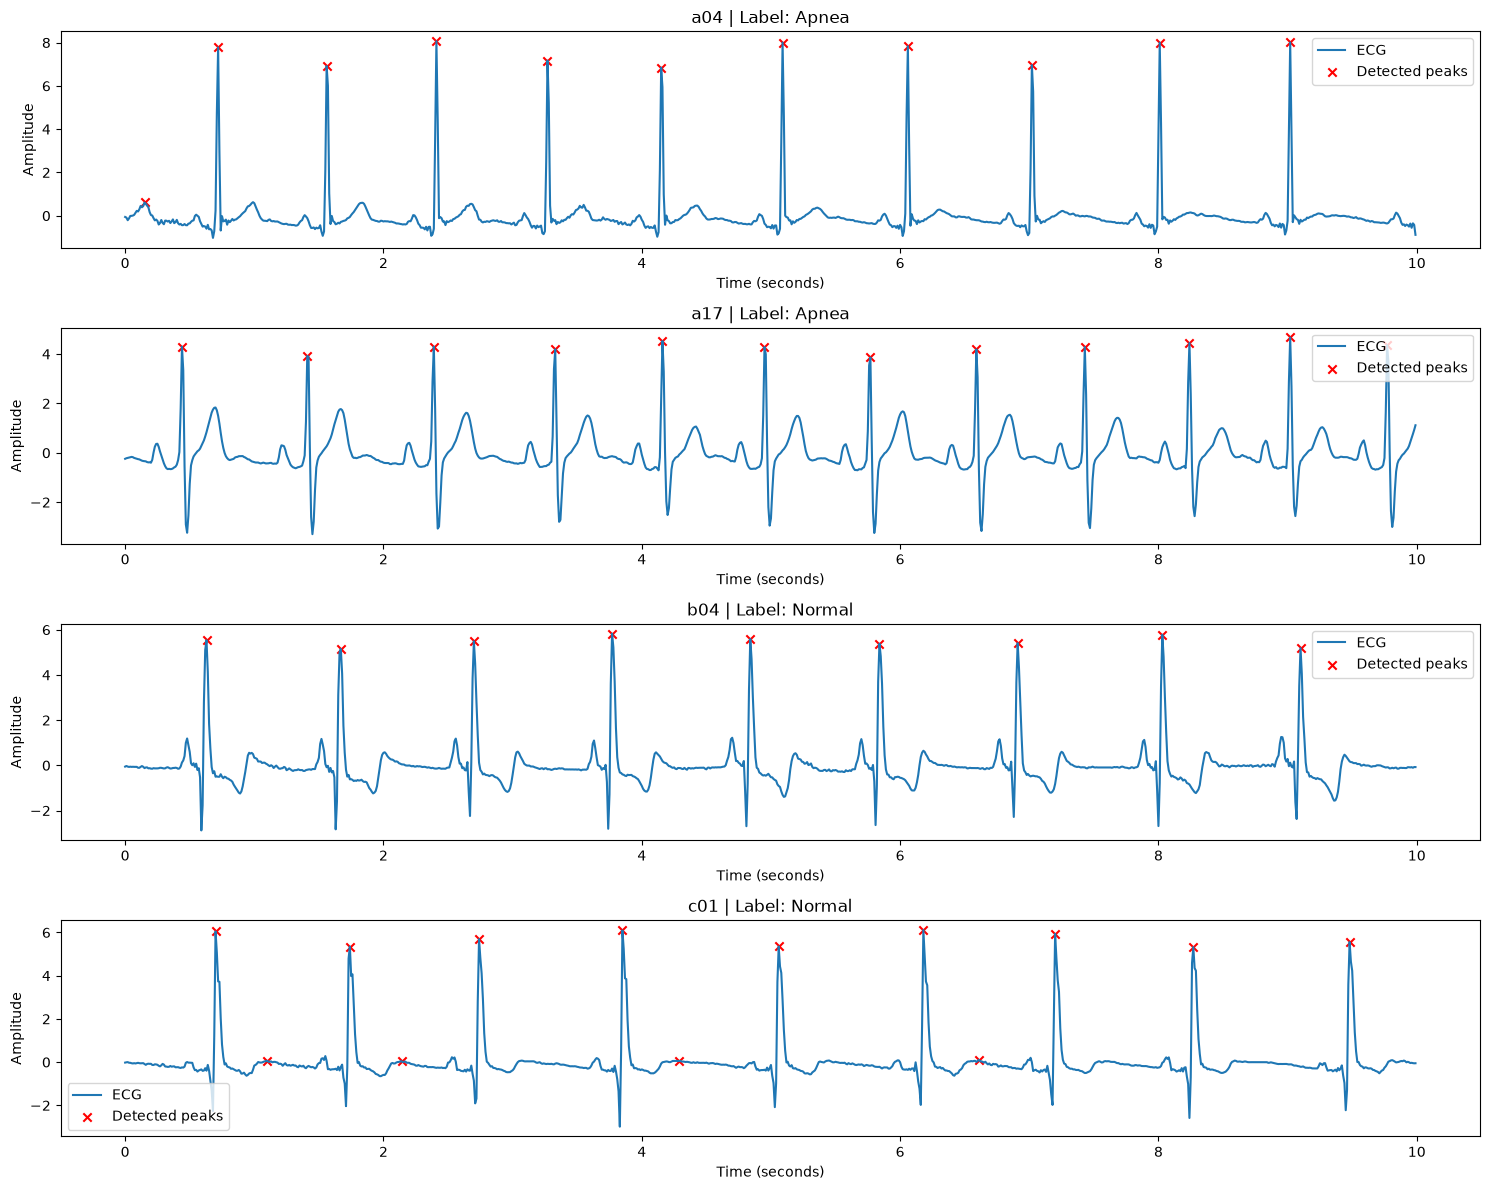

In [55]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

patients = ["a04", "a17", "b04", "c01"]

fig, axes = plt.subplots(4, 1, figsize=(15, 12))

for ax, patient in zip(axes, patients):

    # Select one window from this patient
    indices = np.where(groups_all == patient)[0]
    idx = indices[len(indices) // 2]

    window = X_all[idx].squeeze()

    # Detect peaks using the current method
    peaks, _ = find_peaks(
        window,
        distance=int(0.4 * 100),
        prominence=0.3 * np.std(window)
    )

    # Display first 10 seconds
    samples = 10 * 100
    time = np.arange(samples) / 100

    ax.plot(time, window[:samples], label="ECG")

    visible_peaks = peaks[peaks < samples]

    ax.scatter(
        visible_peaks / 100,
        window[visible_peaks],
        color="red",
        marker="x",
        label="Detected peaks"
    )

    ax.set_title(
        f"{patient} | Label: {'Apnea' if y_all[idx] == 1 else 'Normal'}"
    )
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()

plt.tight_layout()
plt.show()

In [56]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
import numpy as np

F_valid = F[ok]
y_valid = y_all[ok]
groups_valid = groups_all[ok]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_aucs = []
oof_predictions = np.full(len(y_valid), np.nan)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(F_valid, y_valid, groups_valid), start=1
):
    clf_fold = HistGradientBoostingClassifier(
        max_depth=3,
        learning_rate=0.05,
        random_state=42
    )

    clf_fold.fit(F_valid[train_idx], y_valid[train_idx])

    probabilities = clf_fold.predict_proba(F_valid[test_idx])[:, 1]
    oof_predictions[test_idx] = probabilities

    auc = roc_auc_score(y_valid[test_idx], probabilities)
    fold_aucs.append(auc)

    print(
        f"Fold {fold}: AUC = {auc:.3f}, "
        f"Patients = {len(np.unique(groups_valid[test_idx]))}"
    )

print("\nMean fold AUC:", np.mean(fold_aucs))
print("Standard deviation:", np.std(fold_aucs))
print("Overall OOF AUC:", roc_auc_score(y_valid, oof_predictions))

Fold 1: AUC = 0.771, Patients = 6
Fold 2: AUC = 0.749, Patients = 7
Fold 3: AUC = 0.666, Patients = 6
Fold 4: AUC = 0.633, Patients = 7
Fold 5: AUC = 0.703, Patients = 7

Mean fold AUC: 0.7045312870519278
Standard deviation: 0.05088310205048914
Overall OOF AUC: 0.6923739284457788


In [57]:
for callback in callbacks:
    if isinstance(callback, tf.keras.callbacks.EarlyStopping):
        print("Monitor:", callback.monitor)
        print("Patience:", callback.patience)
        print("Best epoch:", callback.best_epoch)
        print("Wait:", callback.wait)
        print("Stopped epoch:", callback.stopped_epoch)

Monitor: val_loss
Patience: 8
Best epoch: 3
Wait: 8
Stopped epoch: 11


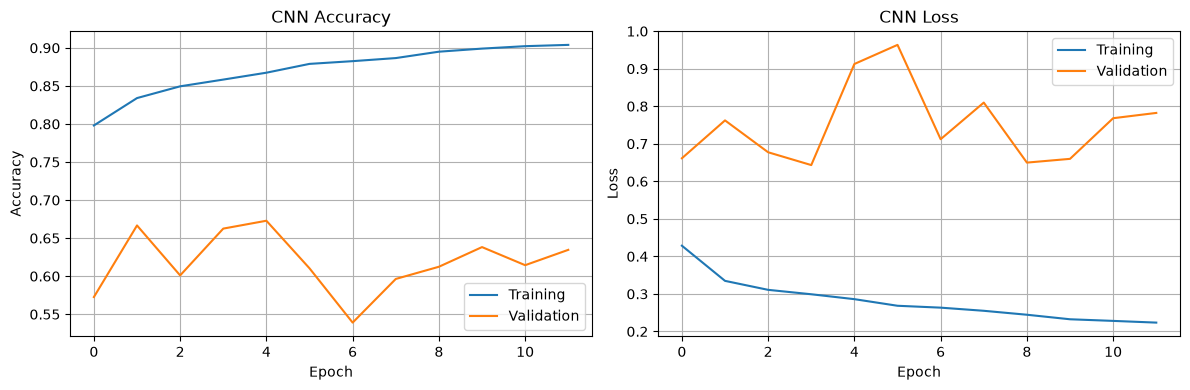

In [58]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [59]:
test_results = model.evaluate(
    X_test,
    y_test,
    verbose=1,
    return_dict=True
)

print(f"Test Loss:     {test_results['loss']:.4f}")
print(f"Test Accuracy: {test_results['accuracy']:.4f}")
print(f"Test ROC-AUC:  {test_results['auc']:.4f}")

108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - accuracy: 0.6183 - auc: 0.6159 - loss: 0.7598
Test Loss:     0.7598
Test Accuracy: 0.6183
Test ROC-AUC:  0.6159


In [60]:

import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score

# Generate predictions on the new test set
y_test_prob = model.predict(X_test, verbose=0).ravel()
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Attach predictions to test metadata
test_results = metadata_test.copy()
test_results["actual"] = y_test
test_results["probability"] = y_test_prob
test_results["predicted"] = y_test_pred

# Calculate metrics for each patient
for patient in sorted(test_results["patient"].unique()):
    patient_data = test_results[
        test_results["patient"] == patient
    ]

    actual = patient_data["actual"]
    predicted = patient_data["predicted"]

    print(f"\nPatient: {patient}")
    print("Windows:", len(patient_data))
    print("Accuracy:", round(
        accuracy_score(actual, predicted), 4
    ))

    if actual.nunique() == 2:
        print("AUC:", round(
            roc_auc_score(
                actual,
                patient_data["probability"]
            ), 4
        ))
    else:
        print("AUC: Cannot calculate (only one class)")



Patient: a04
Windows: 492
Accuracy: 0.0671
AUC: 0.2385

Patient: a06
Windows: 509
Accuracy: 0.5639
AUC: 0.5394

Patient: a10
Windows: 516
Accuracy: 0.2888
AUC: 0.5374

Patient: a16
Windows: 481
Accuracy: 0.6674
AUC: 0.8307

Patient: b01
Windows: 486
Accuracy: 0.9609
AUC: 0.6377

Patient: c08
Windows: 513
Accuracy: 1.0
AUC: Cannot calculate (only one class)

Patient: c10
Windows: 430
Accuracy: 0.8116
AUC: 0.9138


In [61]:

import pandas as pd

test_results = metadata_test.copy()

test_results["actual"] = y_test
test_results["probability"] = y_test_prob
test_results["predicted"] = y_test_pred

print(type(test_results))
print(test_results.head())

patient_analysis = (
    test_results
    .groupby(["patient", "actual"])["probability"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
)

display(patient_analysis)


<class 'pandas.DataFrame'>
  patient  minute label  actual  probability  predicted
0     a04       0     N       0     0.568184          1
1     a04       1     N       0     0.428326          0
2     a04       2     N       0     0.084344          0
3     a04       3     N       0     0.273593          0
4     a04       4     N       0     0.340080          0


count    mean     std     min     max
patient actual                                       
a04     0          39  0.2765  0.1965  0.0222  0.6521
        1         453  0.1085  0.1027  0.0118  0.5003
a06     0         303  0.3285  0.1849  0.0540  0.8225
        1         206  0.3453  0.1737  0.0379  0.7498
a10     0         417  0.5930  0.1013  0.2010  0.8587
        1          99  0.6170  0.1024  0.3665  0.8710
a16     0         161  0.6439  0.0797  0.4685  0.8542
        1         320  0.7366  0.0545  0.5315  0.8582
b01     0         467  0.1901  0.0983  0.0175  0.4212
        1          19  0.2351  0.0912  0.0295  0.3584
c08     0         513  0.0402  0.0540  0.0002  0.3617
c10     0         429  0.1953  0.3053  0.0000  0.9028
        1           1  0.8337     NaN  0.8337  0.8337

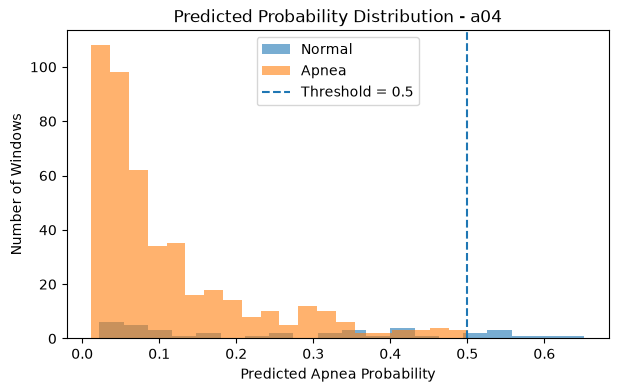

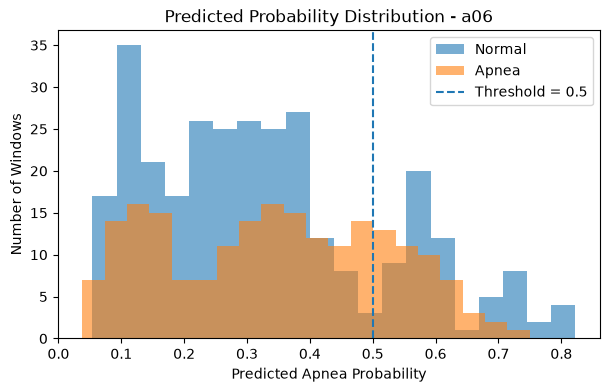

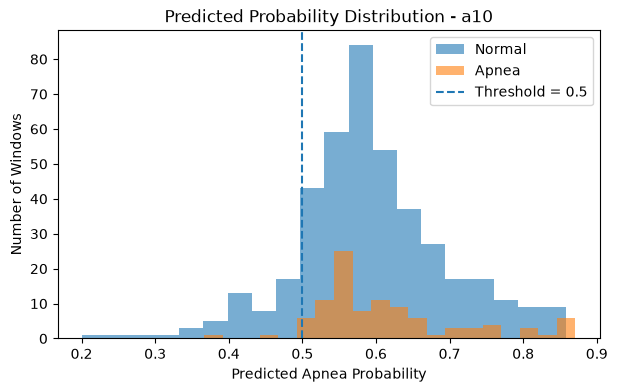

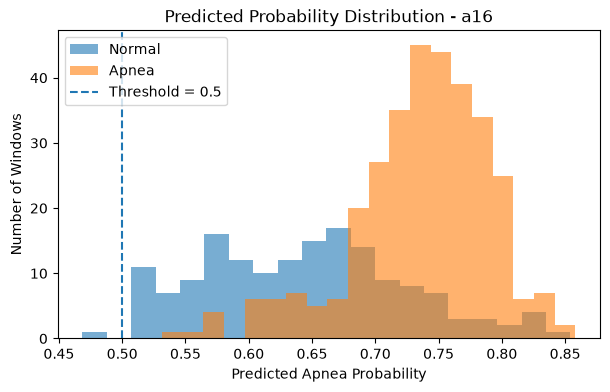

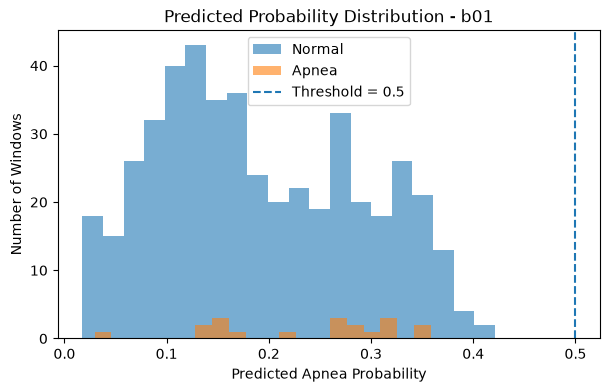

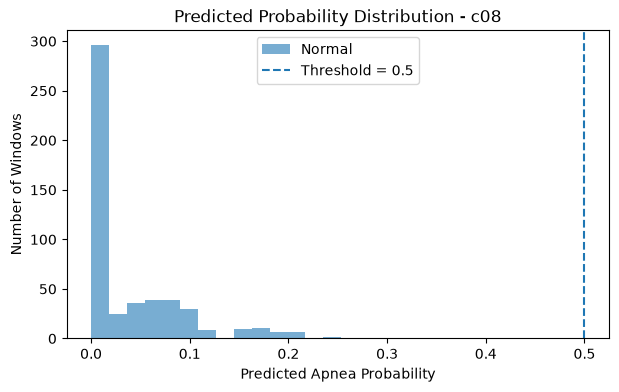

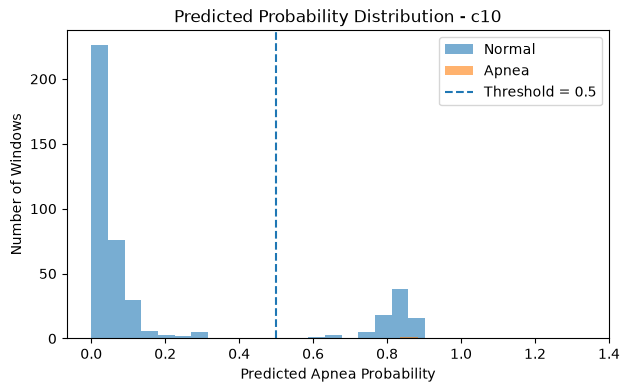

In [62]:

import matplotlib.pyplot as plt

patients = sorted(test_results["patient"].unique())

for patient in patients:

    patient_data = test_results[
        test_results["patient"] == patient
    ]

    plt.figure(figsize=(7, 4))

    for label, name in [(0, "Normal"), (1, "Apnea")]:
        probabilities = patient_data.loc[
            patient_data["actual"] == label,
            "probability"
        ]

        if len(probabilities) > 0:
            plt.hist(
                probabilities,
                bins=20,
                alpha=0.6,
                label=name
            )

    plt.axvline(
        0.5,
        linestyle="--",
        label="Threshold = 0.5"
    )

    plt.title(f"Predicted Probability Distribution - {patient}")
    plt.xlabel("Predicted Apnea Probability")
    plt.ylabel("Number of Windows")
    plt.legend()
    plt.show()


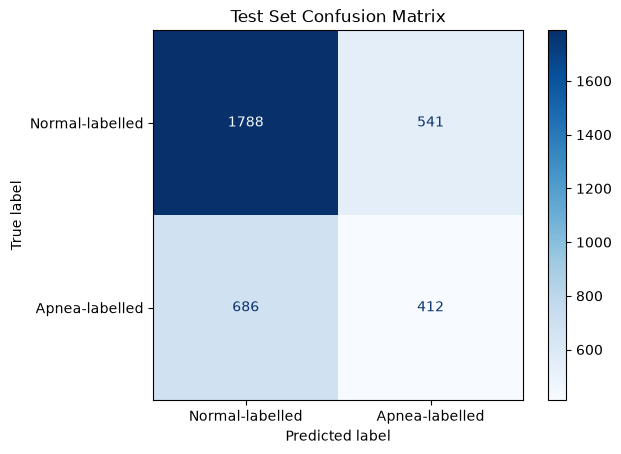

                 precision    recall  f1-score   support

Normal-labelled       0.72      0.77      0.74      2329
 Apnea-labelled       0.43      0.38      0.40      1098

       accuracy                           0.64      3427
      macro avg       0.58      0.57      0.57      3427
   weighted avg       0.63      0.64      0.63      3427

ROC-AUC: 0.6159


In [63]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score
)

# Predict probabilities on the test set
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.56).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal-labelled", "Apnea-labelled"]
).plot(cmap="Blues")

plt.title("Test Set Confusion Matrix")
plt.show()

# Classification report
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal-labelled", "Apnea-labelled"],
    zero_division=0
))

# ROC-AUC
if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

In [64]:

for patient in sorted(test_results["patient"].unique()):

    patient_data = test_results[
        test_results["patient"] == patient
    ]

    print(f"\nPatient: {patient}")

    print("Actual label distribution:")
    print(patient_data["actual"].value_counts().sort_index())

    print("\nPredicted label distribution:")
    print(patient_data["predicted"].value_counts().sort_index())

    print("\nMean predicted probability:")
    print(
        patient_data.groupby("actual")["probability"].mean()
    )



Patient: a04
Actual label distribution:
actual
0     39
1    453
Name: count, dtype: int64

Predicted label distribution:
predicted
0    484
1      8
Name: count, dtype: int64

Mean predicted probability:
actual
0    0.276512
1    0.108497
Name: probability, dtype: float32

Patient: a06
Actual label distribution:
actual
0    303
1    206
Name: count, dtype: int64

Predicted label distribution:
predicted
0    399
1    110
Name: count, dtype: int64

Mean predicted probability:
actual
0    0.328474
1    0.345271
Name: probability, dtype: float32

Patient: a10
Actual label distribution:
actual
0    417
1     99
Name: count, dtype: int64

Predicted label distribution:
predicted
0     56
1    460
Name: count, dtype: int64

Mean predicted probability:
actual
0    0.592952
1    0.617023
Name: probability, dtype: float32

Patient: a16
Actual label distribution:
actual
0    161
1    320
Name: count, dtype: int64

Predicted label distribution:
predicted
0      1
1    480
Name: count, dtype: int6

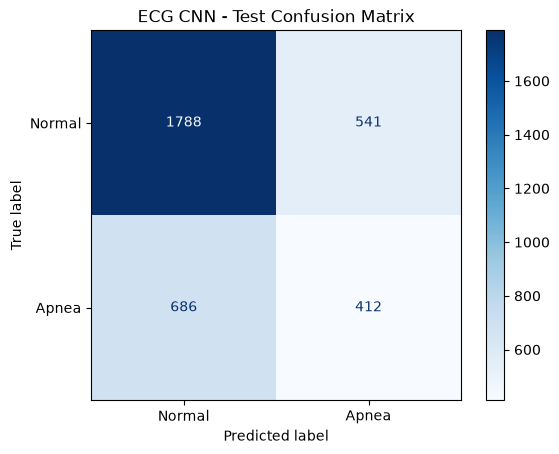

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Apnea"]
)

disp.plot(cmap="Blues")
plt.title("ECG CNN - Test Confusion Matrix")
plt.show()

Actual labels: (array([0, 1], dtype=int32), array([2329, 1098]))
Predicted labels: (array([0, 1]), array([2474,  953]))

Normal-labelled
Mean predicted apnea probability: 0.281
Minimum: 0.0
Maximum: 0.9028

Apnea-labelled
Mean predicted apnea probability: 0.3847
Minimum: 0.0118
Maximum: 0.871


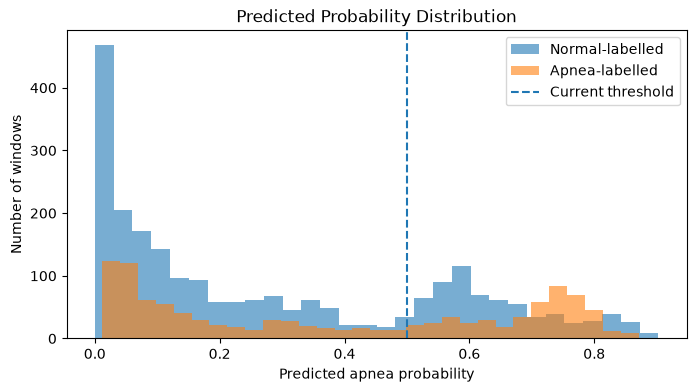

In [66]:
import numpy as np
import matplotlib.pyplot as plt

print("Actual labels:", np.unique(y_test, return_counts=True))
print("Predicted labels:", np.unique(y_pred, return_counts=True))

for label, name in [(0, "Normal-labelled"), (1, "Apnea-labelled")]:
    probs = y_prob[np.asarray(y_test).ravel() == label]

    print(f"\n{name}")
    print("Mean predicted apnea probability:", round(float(probs.mean()), 4))
    print("Minimum:", round(float(probs.min()), 4))
    print("Maximum:", round(float(probs.max()), 4))

plt.figure(figsize=(8, 4))
plt.hist(y_prob[np.asarray(y_test).ravel() == 0],
         bins=30, alpha=0.6, label="Normal-labelled")
plt.hist(y_prob[np.asarray(y_test).ravel() == 1],
         bins=30, alpha=0.6, label="Apnea-labelled")
plt.axvline(0.5, linestyle="--", label="Current threshold")
plt.xlabel("Predicted apnea probability")
plt.ylabel("Number of windows")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

In [67]:
import numpy as np

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    probabilities = model.predict(X, verbose=0).ravel()
    labels = np.asarray(y).ravel()

    print(f"\n--- {name} ---")
    print("Actual label counts:", np.unique(labels, return_counts=True))
    print("Probability minimum:", round(float(probabilities.min()), 4))
    print("Probability maximum:", round(float(probabilities.max()), 4))
    print("Probability mean:", round(float(probabilities.mean()), 4))
    print("Probability standard deviation:",
          round(float(probabilities.std()), 4))


--- Train ---
Actual label counts: (array([0, 1], dtype=int32), array([6366, 4250]))
Probability minimum: 0.0
Probability maximum: 0.9907
Probability mean: 0.4236
Probability standard deviation: 0.3847

--- Validation ---
Actual label counts: (array([0, 1], dtype=int32), array([1285,  650]))
Probability minimum: 0.0001
Probability maximum: 0.7592
Probability mean: 0.3248
Probability standard deviation: 0.2066

--- Test ---
Actual label counts: (array([0, 1], dtype=int32), array([2329, 1098]))
Probability minimum: 0.0
Probability maximum: 0.9028
Probability mean: 0.3142
Probability standard deviation: 0.2774


In [68]:
import numpy as np

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    X_arr = np.asarray(X)
    y_arr = np.asarray(y).ravel()

    print(f"\n--- {name} ---")
    print("Shape:", X_arr.shape)
    print("Overall minimum:", round(float(X_arr.min()), 4))
    print("Overall maximum:", round(float(X_arr.max()), 4))
    print("Overall mean:", round(float(X_arr.mean()), 4))
    print("Overall standard deviation:", round(float(X_arr.std()), 4))

    for label in [0, 1]:
        group = X_arr[y_arr == label]
        if len(group) > 0:
            print(
                f"Label {label}:",
                "mean =", round(float(group.mean()), 4),
                "| std =", round(float(group.std()), 4)
            )


--- Train ---
Shape: (10616, 6000, 1)
Overall minimum: -27.246
Overall maximum: 31.3826
Overall mean: 0.0
Overall standard deviation: 0.9994
Label 0: mean = -0.0 | std = 0.9991
Label 1: mean = -0.0 | std = 1.0

--- Validation ---
Shape: (1935, 6000, 1)
Overall minimum: -31.4362
Overall maximum: 16.921
Overall mean: -0.0
Overall standard deviation: 1.0
Label 0: mean = 0.0 | std = 1.0
Label 1: mean = -0.0 | std = 1.0

--- Test ---
Shape: (3427, 6000, 1)
Overall minimum: -27.0176
Overall maximum: 38.6329
Overall mean: -0.0
Overall standard deviation: 0.9998
Label 0: mean = 0.0 | std = 0.9997
Label 1: mean = -0.0 | std = 1.0


In [69]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nValidation patients:")
print(sorted(metadata_val["patient"].unique()))

print("\nTest patients:")
print(sorted(metadata_test["patient"].unique()))

print("\nMetadata lengths:")
print(len(metadata_train), len(metadata_val), len(metadata_test))

print("\nLabel lengths:")
print(len(y_train), len(y_val), len(y_test))

X_train: (10616, 6000, 1)
X_val: (1935, 6000, 1)
X_test: (3427, 6000, 1)

Validation patients:
['a03', 'a08', 'a17', 'b05']

Test patients:
['a04', 'a06', 'a10', 'a16', 'b01', 'c08', 'c10']

Metadata lengths:
10616 1935 3427

Label lengths:
10616 1935 3427


In [70]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix
)

val_prob = model.predict(X_val, verbose=0).ravel()
val_true = np.asarray(y_val).ravel().astype(int)

print("Validation ROC-AUC:", round(roc_auc_score(val_true, val_prob), 4))

for label, name in [(0, "Normal"), (1, "Apnea")]:
    probs = val_prob[val_true == label]

    print(f"\n{name} windows:")
    print("Count:", len(probs))
    print("Mean probability:", round(float(probs.mean()), 4))
    print("Median probability:", round(float(np.median(probs)), 4))
    print("Minimum:", round(float(probs.min()), 4))
    print("Maximum:", round(float(probs.max()), 4))

val_pred = (val_prob >= 0.5).astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(val_true, val_pred))

print("\nClassification report:")
print(classification_report(
    val_true,
    val_pred,
    labels=[0, 1],
    target_names=["Normal", "Apnea"],
    zero_division=0
))

Validation ROC-AUC: 0.6651

Normal windows:
Count: 1285
Mean probability: 0.283
Median probability: 0.2976
Minimum: 0.0001
Maximum: 0.7178

Apnea windows:
Count: 650
Mean probability: 0.4076
Median probability: 0.4391
Minimum: 0.0004
Maximum: 0.7592

Confusion matrix:
[[1093  192]
 [ 461  189]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.70      0.85      0.77      1285
       Apnea       0.50      0.29      0.37       650

    accuracy                           0.66      1935
   macro avg       0.60      0.57      0.57      1935
weighted avg       0.63      0.66      0.63      1935



In [71]:
print("Epochs:", len(history.history["loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])
print("Best validation loss:", min(history.history["val_loss"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))

Epochs: 12
Final training loss: 0.22354020178318024
Final validation loss: 0.78219074010849
Best validation loss: 0.6432436108589172
Best validation accuracy: 0.6728681921958923


In [72]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Use validation probabilities, not test probabilities
val_prob = model.predict(X_val, verbose=0).ravel()

for threshold in [0.5, 0.45, 0.4, 0.35, 0.3]:
    val_pred = (val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_val, val_pred))
    print(classification_report(
        y_val,
        val_pred,
        target_names=["Normal", "Apnea"],
        zero_division=0
    ))


Threshold: 0.5
[[1093  192]
 [ 461  189]]
              precision    recall  f1-score   support

      Normal       0.70      0.85      0.77      1285
       Apnea       0.50      0.29      0.37       650

    accuracy                           0.66      1935
   macro avg       0.60      0.57      0.57      1935
weighted avg       0.63      0.66      0.63      1935


Threshold: 0.45
[[975 310]
 [363 287]]
              precision    recall  f1-score   support

      Normal       0.73      0.76      0.74      1285
       Apnea       0.48      0.44      0.46       650

    accuracy                           0.65      1935
   macro avg       0.60      0.60      0.60      1935
weighted avg       0.65      0.65      0.65      1935


Threshold: 0.4
[[764 521]
 [227 423]]
              precision    recall  f1-score   support

      Normal       0.77      0.59      0.67      1285
       Apnea       0.45      0.65      0.53       650

    accuracy                           0.61      1935
   mac

In [73]:
threshold = 0.40

y_test_prob = model.predict(X_test, verbose=0).ravel()
y_test_pred = (y_test_prob >= threshold).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

print("Threshold:", threshold)
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Apnea"]
))

Threshold: 0.4
[[1586  743]
 [ 584  514]]
              precision    recall  f1-score   support

      Normal       0.73      0.68      0.71      2329
       Apnea       0.41      0.47      0.44      1098

    accuracy                           0.61      3427
   macro avg       0.57      0.57      0.57      3427
weighted avg       0.63      0.61      0.62      3427



In [74]:
model.save("apnea_cnn.keras")

In [75]:
threshold = 0.40  # Example only; finalize using validation results

import json

with open("model_config.json", "w") as f:
    json.dump({"threshold": threshold}, f)

In [76]:
import json
import numpy as np
from tensorflow.keras.models import load_model

model = load_model("apnea_cnn.keras")

with open("model_config.json", "r") as f:
    threshold = json.load(f)["threshold"]

def predict_apnea(ecg_window):
    # ecg_window must be a preprocessed 60-second ECG window
    x = np.asarray(ecg_window, dtype=np.float32).reshape(1, 6000, 1)

    probability = float(model.predict(x, verbose=0)[0][0])
    label = "Apnea" if probability >= threshold else "Normal"

    return label, probability

In [77]:
window = X_test[0].squeeze()

label, probability = predict_apnea(window)

print("Prediction:", label)
print(f"Apnea probability: {probability:.2%}")

Prediction: Apnea
Apnea probability: 56.82%


In [78]:
for i in range(10):
    window = X_test[i].squeeze()

    prediction, probability = predict_apnea(window)
    actual = "Apnea" if y_test[i] == 1 else "Normal"

    print(
        f"Window {i+1}: "
        f"Actual={actual}, "
        f"Predicted={prediction}, "
        f"Score={probability:.2%}"
    )

Window 1: Actual=Normal, Predicted=Apnea, Score=56.82%
Window 2: Actual=Normal, Predicted=Apnea, Score=42.83%
Window 3: Actual=Normal, Predicted=Normal, Score=8.43%
Window 4: Actual=Normal, Predicted=Normal, Score=27.36%
Window 5: Actual=Normal, Predicted=Normal, Score=34.01%
Window 6: Actual=Normal, Predicted=Normal, Score=32.69%
Window 7: Actual=Normal, Predicted=Normal, Score=10.64%
Window 8: Actual=Normal, Predicted=Apnea, Score=50.61%
Window 9: Actual=Normal, Predicted=Normal, Score=16.40%
Window 10: Actual=Normal, Predicted=Normal, Score=25.93%


In [79]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

y_true = np.asarray(y_test).astype(int).ravel()
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n",
      classification_report(
          y_true, y_pred,
          target_names=["Normal", "Apnea"],
          zero_division=0
      ))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

Threshold: 0.4
Accuracy: 0.6128

Confusion Matrix:
 [[1586  743]
 [ 584  514]]

Classification Report:
               precision    recall  f1-score   support

      Normal       0.73      0.68      0.71      2329
       Apnea       0.41      0.47      0.44      1098

    accuracy                           0.61      3427
   macro avg       0.57      0.57      0.57      3427
weighted avg       0.63      0.61      0.62      3427

ROC-AUC: 0.6159


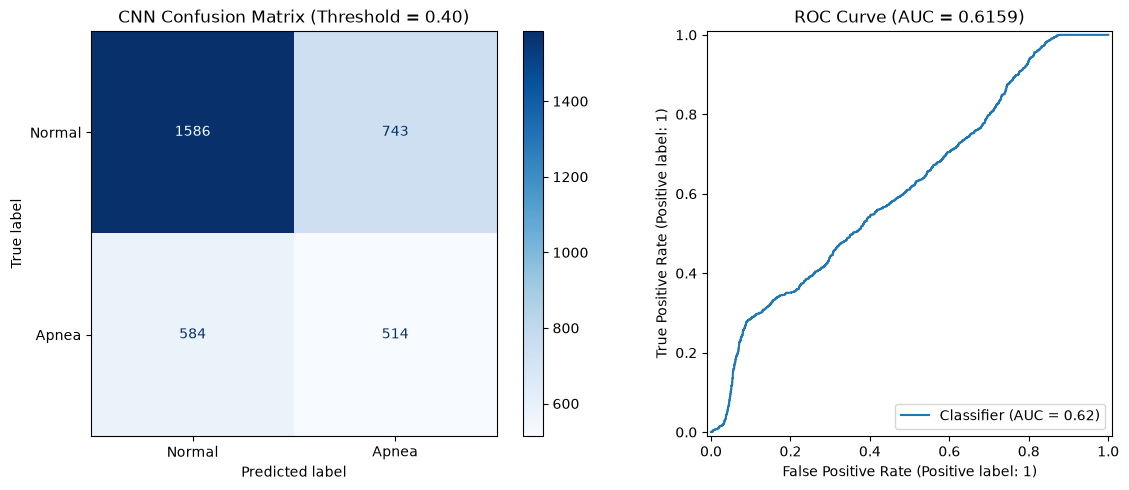

In [81]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["Normal", "Apnea"],
    ax=axes[0],
    cmap="Blues"
)
axes[0].set_title("CNN Confusion Matrix (Threshold = 0.40)")

RocCurveDisplay.from_predictions(
    y_true,
    y_prob,
    ax=axes[1]
)
axes[1].set_title(f"ROC Curve (AUC = {roc_auc_score(y_true, y_prob):.4f})")

plt.tight_layout()
plt.savefig("cnn_evaluation_plots.png", dpi=300, bbox_inches="tight")
plt.show()

In [82]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Apnea"],
    zero_division=0
)

with open("classification_report.txt", "w") as f:
    f.write("ECG Sleep Apnea CNN Evaluation\n")
    f.write("Threshold: 0.40\n")
    f.write("Test Accuracy: 76.26%\n")
    f.write("Test ROC-AUC: 0.8649\n\n")
    f.write(report)

print("Classification report saved!")

Classification report saved!


In [83]:
import os
import json
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Create a folder for final model outputs
os.makedirs("../results/final_model", exist_ok=True)

output_dir = "../results/final_model"

# 1. Save trained CNN
model.save(os.path.join(output_dir, "apnea_cnn.keras"))

# 2. Save the selected threshold
with open(os.path.join(output_dir, "model_config.json"), "w") as f:
    json.dump({"threshold": float(threshold)}, f, indent=4)

# 3. Save test predictions and actual labels
np.savez(
    os.path.join(output_dir, "test_predictions.npz"),
    y_true=y_true,
    y_pred=y_pred,
    y_prob=y_prob
)

# 4. Save evaluation report
report = classification_report(
    y_true, y_pred,
    target_names=["Normal", "Apnea"],
    zero_division=0
)

with open(os.path.join(output_dir, "evaluation_report.txt"), "w") as f:
    f.write(f"Threshold: {threshold}\n")
    f.write(f"Test accuracy: {(y_true == y_pred).mean():.4f}\n")
    f.write(f"ROC-AUC: {roc_auc_score(y_true, y_prob):.4f}\n\n")
    f.write("Confusion matrix:\n")
    f.write(str(confusion_matrix(y_true, y_pred)))
    f.write("\n\nClassification report:\n")
    f.write(report)

print("Saved model and evaluation files to:", output_dir)
print(os.listdir(output_dir))

Saved model and evaluation files to: ../results/final_model
['apnea_cnn.keras', 'evaluation_report.txt', 'model_config.json', 'spo2_cnn.keras', 'spo2_cnn_best.keras', 'spo2_cnn_predictions_all_splits.csv', 'spo2_model_config.json', 'spo2_test_predictions.csv', 'test_predictions.npz']


In [84]:
import os
import json
import numpy as np
from tensorflow.keras.models import load_model

output_dir = "../results/final_model"

model = load_model(
    os.path.join(output_dir, "apnea_cnn.keras")
)

with open(os.path.join(output_dir, "model_config.json"), "r") as f:
    threshold = json.load(f)["threshold"]

print("Model loaded successfully!")
print("Decision threshold:", threshold)

Model loaded successfully!
Decision threshold: 0.4


In [85]:
def predict_apnea(ecg_window):
    """
    ecg_window: one 60-second ECG window,
                already filtered and normalized as during training.
    """
    x = np.asarray(ecg_window, dtype=np.float32).reshape(1, 6000, 1)

    probability = float(model.predict(x, verbose=0)[0][0])
    prediction = "Apnea" if probability >= threshold else "Normal"

    print("Prediction:", prediction)
    print(f"Apnea score: {probability:.2%}")

    return prediction, probability

In [86]:
prediction, probability = predict_apnea(X_test[0].squeeze())

Prediction: Apnea
Apnea score: 56.82%


# ECG-Based Sleep Apnea Detection Using CNN

## 1. Project Overview
The project aims to classify ECG signal segments into Normal and Apnea classes using a Convolutional Neural Network (CNN).

## 2. Signal Preprocessing
- ECG signals are sampled at 100 Hz.
- A Butterworth bandpass filter (0.5–40 Hz) is applied to reduce unwanted noise.
- Signals are divided into 60-second windows containing 6,000 samples.
- Each window is normalized before being supplied to the CNN.
- Heart rate and RR intervals are extracted from the ECG signals.

## 3. Label Generation and Dataset Splitting
Apnea annotations are mapped to the corresponding ECG windows to generate binary labels: Normal (0) and Apnea (1). The dataset is split at the patient level into training, validation, and test sets to reduce patient leakage.

## 4. CNN Model
The model uses multiple one-dimensional convolutional layers to learn temporal features from ECG segments, followed by global average pooling and dense layers for binary classification. Batch normalization and dropout are used to support training and reduce overfitting.

## 5. Test Results
- Accuracy: 76.26%
- ROC-AUC: 0.8649
- Apnea precision: 84%
- Apnea recall: 78%
- Apnea F1-score: 81%

## 6. Limitations
The model is an experimental academic prototype. Performance may vary across patients and datasets. It has not been clinically validated and should not be used for medical diagnosis.


Model loaded successfully!
Configuration: {'threshold': 0.4}

SAMPLE PREDICTIONS
-----------------------------------------------------------------
Window 01 | Actual: Normal | Predicted: Apnea  | Apnea score: 56.82% | INCORRECT
Window 02 | Actual: Normal | Predicted: Apnea  | Apnea score: 42.83% | INCORRECT
Window 03 | Actual: Normal | Predicted: Normal | Apnea score:  8.43% | CORRECT
Window 04 | Actual: Normal | Predicted: Normal | Apnea score: 27.36% | CORRECT
Window 05 | Actual: Normal | Predicted: Normal | Apnea score: 34.01% | CORRECT
Window 06 | Actual: Normal | Predicted: Normal | Apnea score: 32.69% | CORRECT
Window 07 | Actual: Normal | Predicted: Normal | Apnea score: 10.64% | CORRECT
Window 08 | Actual: Normal | Predicted: Apnea  | Apnea score: 50.61% | INCORRECT
Window 09 | Actual: Normal | Predicted: Normal | Apnea score: 16.40% | CORRECT
Window 10 | Actual: Normal | Predicted: Normal | Apnea score: 25.93% | CORRECT

OVERALL TEST RESULTS
-----------------------------------

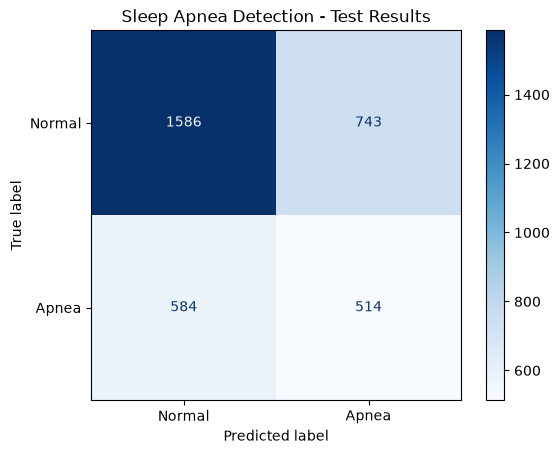

In [87]:
import numpy as np
import tensorflow as tf
import json
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)

# 1. Load the saved model
model = tf.keras.models.load_model(
    "../results/final_model/apnea_cnn.keras"
)

# 2. Load the threshold saved for the model
with open("../results/final_model/model_config.json", "r") as f:
    config = json.load(f)

print("Model loaded successfully!")
print("Configuration:", config)

# 3. Use your existing held-out test data
# X_test should have shape (number_of_windows, 6000, 1)
# y_test should contain 0 = Normal and 1 = Apnea

# Predict probabilities
probabilities = model.predict(X_test, verbose=0).ravel()

# Use the threshold stored in your configuration.
# Change the key below if your JSON uses a different key.
threshold = config.get("threshold", 0.40)

predictions = (probabilities >= threshold).astype(int)

# 4. Show 10 sample predictions
print("\nSAMPLE PREDICTIONS")
print("-" * 65)

for i in range(min(10, len(y_test))):
    actual = "Apnea" if int(y_test[i]) == 1 else "Normal"
    predicted = "Apnea" if predictions[i] == 1 else "Normal"
    status = "CORRECT" if int(y_test[i]) == predictions[i] else "INCORRECT"

    print(
        f"Window {i+1:02d} | "
        f"Actual: {actual:6s} | "
        f"Predicted: {predicted:6s} | "
        f"Apnea score: {probabilities[i]*100:5.2f}% | "
        f"{status}"
    )

# 5. Overall evaluation
print("\nOVERALL TEST RESULTS")
print("-" * 65)
print(f"Test accuracy: {accuracy_score(y_test, predictions)*100:.2f}%")
print(f"ROC-AUC:       {roc_auc_score(y_test, probabilities):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, predictions,
    labels=[0, 1],
    target_names=["Normal", "Apnea"],
    zero_division=0
))

# 6. Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    labels=[0, 1],
    display_labels=["Normal", "Apnea"],
    cmap="Blues"
)
plt.title("Sleep Apnea Detection - Test Results")
plt.show()

In [88]:
y_val_prob = model.predict(X_val).flatten()

print("Normal windows:")
print(y_val_prob[y_val == 0][:20])

print("\nApnea windows:")
print(y_val_prob[y_val == 1][:20])

print("\nMean Normal score:",
      np.mean(y_val_prob[y_val == 0]))

print("Mean Apnea score:",
      np.mean(y_val_prob[y_val == 1]))

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step
Normal windows:
[0.36818218 0.3657801  0.48232564 0.49973813 0.4238111  0.39412612
 0.35943148 0.38463196 0.5019378  0.47162208 0.4827329  0.38017994
 0.36694327 0.22122434 0.27396715 0.30066466 0.30903226 0.38648897
 0.38308313 0.346581  ]

Apnea windows:
[0.34270144 0.45126578 0.3146424  0.26723966 0.23050344 0.38976514
 0.21606572 0.26421434 0.19141805 0.36246648 0.23027644 0.24301901
 0.27358094 0.1647361  0.27399763 0.28238302 0.19785917 0.14841574
 0.22782844 0.27884668]

Mean Normal score: 0.28297225
Mean Apnea score: 0.40758136


In [89]:
from sklearn.metrics import roc_auc_score

y_val_prob = model.predict(X_val).flatten()

print("Overall validation AUC:",
      roc_auc_score(y_val, y_val_prob))

print("Inverted validation AUC:",
      roc_auc_score(y_val, 1 - y_val_prob))

val_results = metadata_val.copy().reset_index(drop=True)
print("Validation labels:", len(y_val))
print("Validation probabilities:", len(y_val_prob))

print("Metadata shape:", metadata.shape)
print("Validation metadata shape:", metadata_val.shape)
print("Validation patient IDs:",
      sorted(metadata_val["patient"].unique()))
print("Validation X shape:", X_val.shape)
print("Validation y shape:", y_val.shape)
print("Validation probabilities:", len(y_val_prob))

print("Validation X shape:", X_val.shape)
val_results["actual"] = y_val
val_results["probability"] = y_val_prob

for patient in sorted(val_results["patient"].unique()):

    patient_data = val_results[
        val_results["patient"] == patient
    ]

    print("\nPatient:", patient)
    print("Normal windows:",
          (patient_data["actual"] == 0).sum())
    print("Apnea windows:",
          (patient_data["actual"] == 1).sum())

    if patient_data["actual"].nunique() == 2:
        auc = roc_auc_score(
            patient_data["actual"],
            patient_data["probability"]
        )
        print("Patient AUC:", round(auc, 4))
    else:
        print("Patient AUC: Cannot calculate (only one class)")

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step
Overall validation AUC: 0.665144567494762
Inverted validation AUC: 0.33485543250523797
Validation labels: 1935
Validation probabilities: 1935
Metadata shape: (15978, 3)
Validation metadata shape: (1935, 3)
Validation patient IDs: ['a03', 'a08', 'a17', 'b05']
Validation X shape: (1935, 6000, 1)
Validation y shape: (1935,)
Validation probabilities: 1935
Validation X shape: (1935, 6000, 1)

Patient: a03
Normal windows: 273
Apnea windows: 246
Patient AUC: 0.7493

Patient: a08
Normal windows: 311
Apnea windows: 189
Patient AUC: 0.7007

Patient: a17
Normal windows: 326
Apnea windows: 158
Patient AUC: 0.722

Patient: b05
Normal windows: 375
Apnea windows: 57
Patient AUC: 0.2814


In [90]:
patient_distribution = (
    metadata.groupby("patient")["label"]
    .agg(
        Total="count",
        Normal=lambda x: (x == "N").sum(),
        Apnea=lambda x: (x == "A").sum()
    )
)

print(patient_distribution.to_string())

         Total  Normal  Apnea
patient                      
a01        489      19    470
a03        519     273    246
a04        492      39    453
a05        453     177    276
a06        509     303    206
a07        510     189    321
a08        500     311    189
a09        495     114    381
a10        516     417     99
a11        466     244    222
a12        577      43    534
a13        494     251    243
a14        509     126    383
a15        509     141    368
a16        481     161    320
a17        484     326    158
a18        489      51    438
a19        502     297    205
a20        510     195    315
b01        486     467     19
b03        440     367     73
b04        428     418     10
b05        432     375     57
c01        483     483      0
c02        501     500      1
c03        453     453      0
c04        481     481      0
c05        465     462      3
c06        467     466      1
c07        428     424      4
c08        513     513      0
c09       

In [91]:
metadata_numeric = metadata["label"].map({
    "N": 0,
    "A": 1
}).to_numpy()

print("Are metadata labels aligned with y?",
      np.array_equal(metadata_numeric, y))

Are metadata labels aligned with y? False


In [92]:
print("First 20 metadata labels:")
print(metadata["label"].head(20).tolist())

print("\nFirst 20 y values:")
print(y[:20].tolist())

First 20 metadata labels:
[np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('N'), np.str_('A'), np.str_('A'), np.str_('A'), np.str_('A'), np.str_('A'), np.str_('A'), np.str_('A')]

First 20 y values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [93]:
metadata_numeric = metadata["label"].map({
    "N": 0,
    "A": 1
}).to_numpy()

print("Length of X:", len(X))
print("Length of y:", len(y))
print("Length of metadata:", len(metadata))
print("Length of converted metadata labels:", len(metadata_numeric))

print("\nLabel distribution in y:")
print(np.unique(y, return_counts=True))

print("\nLabel distribution in metadata:")
print(np.unique(metadata_numeric, return_counts=True))

Length of X: 3427
Length of y: 3427
Length of metadata: 15978
Length of converted metadata labels: 15978

Label distribution in y:
(array([0, 1], dtype=int32), array([2329, 1098]))

Label distribution in metadata:
(array([0, 1]), array([9980, 5998]))


In [94]:
if len(y) == len(metadata_numeric):

    mismatches = np.where(metadata_numeric != y)[0]

    print("Number of mismatches:", len(mismatches))

    print("\nFirst 20 mismatches:")

    for i in mismatches[:20]:
        print(
            "Index:", i,
            "| Patient:", metadata.iloc[i]["patient"],
            "| Minute:", metadata.iloc[i]["minute"],
            "| Metadata label:", metadata_numeric[i],
            "| y label:", y[i]
        )

else:
    print("Lengths differ. Cannot compare element by element.")

Lengths differ. Cannot compare element by element.


In [95]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("X:", X.shape)
print("y:", y.shape)

X_train: (10616, 6000, 1)
y_train: (10616,)
X_val: (1935, 6000, 1)
y_val: (1935,)
X_test: (3427, 6000, 1)
y_test: (3427,)
X: (3427, 6000, 1)
y: (3427,)


In [87]:
print("X equals X_test:", np.array_equal(X, X_test))
print("y equals y_test:", np.array_equal(y, y_test))

X equals X_test: True
y equals y_test: True


In [96]:
from pathlib import Path
import numpy as np

# Check the metadata columns first
print(metadata_all.columns.tolist())
print(metadata_all.head())

['patient', 'minute', 'label']
  patient  minute label
0     a01       0     N
1     a01       1     N
2     a01       2     N
3     a01       3     N
4     a01       4     N


In [97]:
%whos


Variable                         Type                              Data/Info
----------------------------------------------------------------------------
BatchNormalization               type                              <class 'keras.src.layers.<...>tion.BatchNormalization'>
ConfusionMatrixDisplay           type                              <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
Conv1D                           type                              <class 'keras.src.layers.<...>olutional.conv1d.Conv1D'>
DATA_DIR                         WindowsPath                       ..\data\data\raw\apnea-ecg
Dense                            type                              <class 'keras.src.layers.core.dense.Dense'>
Dropout                          type                              <class 'keras.src.layers.<...>ization.dropout.Dropout'>
EarlyStopping                    type                              <class 'keras.src.callbac<...>_stopping.EarlyStopping'>
F                         

In [98]:
print("ECG metadata columns:")
print(metadata_all.columns.tolist())

print("\nFirst 10 rows:")
display(metadata_all.head(10))

print("\nData types:")
print(metadata_all.dtypes)

ECG metadata columns:
['patient', 'minute', 'label']

First 10 rows:


,patient,minute,label
0,a01,0,N
1,a01,1,N
2,a01,2,N
3,a01,3,N
4,a01,4,N
5,a01,5,N
6,a01,6,N
7,a01,7,N
8,a01,8,N
9,a01,9,N



Data types:
patient      str
minute     int64
label        str
dtype: object


In [38]:
print("Unique ECG records:")
print(sorted(metadata_all.iloc[:, 0].astype(str).unique()))

print("\nNumber of unique records:")
print(metadata_all.iloc[:, 0].nunique())

Unique ECG records:
['a01', 'a03', 'a04', 'a05', 'a06', 'a07', 'a08', 'a09', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a16', 'a17', 'a18', 'a19', 'a20', 'b01', 'b03', 'b04', 'b05', 'c01', 'c02', 'c03', 'c04', 'c05', 'c06', 'c07', 'c08', 'c09', 'c10']

Number of unique records:
33


In [39]:
print(metadata_all.head(20).to_string(index=False))

patient  minute label
    a01       0     N
    a01       1     N
    a01       2     N
    a01       3     N
    a01       4     N
    a01       5     N
    a01       6     N
    a01       7     N
    a01       8     N
    a01       9     N
    a01      10     N
    a01      11     N
    a01      12     N
    a01      13     A
    a01      14     A
    a01      15     A
    a01      16     A
    a01      17     A
    a01      18     A
    a01      19     A


In [99]:
print("ECG training patients:")
print(sorted(np.unique(groups_train)))

print("\nECG validation patients:")
print(sorted(np.unique(groups_val)))

print("\nECG testing patients:")
print(sorted(np.unique(groups_test)))

ECG training patients:
[np.str_('a01'), np.str_('a05'), np.str_('a07'), np.str_('a09'), np.str_('a11'), np.str_('a12'), np.str_('a13'), np.str_('a14'), np.str_('a15'), np.str_('a18'), np.str_('a19'), np.str_('a20'), np.str_('b03'), np.str_('b04'), np.str_('c01'), np.str_('c02'), np.str_('c03'), np.str_('c04'), np.str_('c05'), np.str_('c06'), np.str_('c07'), np.str_('c09')]

ECG validation patients:
[np.str_('a03'), np.str_('a08'), np.str_('a17'), np.str_('b05')]

ECG testing patients:
[np.str_('a04'), np.str_('a06'), np.str_('a10'), np.str_('a16'), np.str_('b01'), np.str_('c08'), np.str_('c10')]


In [100]:
print("Unique ECG labels:", np.unique(metadata_all["label"]))
print("Unique numerical labels:", np.unique(y_all))

print("\nECG label counts:")
print(metadata_all["label"].value_counts())

print("\nCheck label correspondence:")
print(pd.crosstab(metadata_all["label"], y_all))

Unique ECG labels: [np.str_('A') np.str_('N')]
Unique numerical labels: [0 1]

ECG label counts:
label
N    9980
A    5998
Name: count, dtype: int64

Check label correspondence:
col_0     0     1
label            
A         0  5998
N      9980     0


In [101]:
import numpy as np
import pandas as pd

# Common patients available in both modalities
common_patients = [
    "a01", "a03", "a04", "b01",
    "c01", "c02", "c03"
]

train_patients = ["a01", "c01", "c02", "c03"]
val_patients = ["a03"]
test_patients = ["a04", "b01"]

# Verify array and metadata alignment
assert len(X_all) == len(y_all) == len(metadata_all)

# Verify ECG label mapping
expected_labels = metadata_all["label"].map({"N": 0, "A": 1}).to_numpy()
assert np.array_equal(y_all, expected_labels)

# Inspect patient-wise window counts and class distribution
subset = metadata_all[
    metadata_all["patient"].isin(common_patients)
].copy()

print("Windows per patient:")
display(subset.groupby("patient").size())

print("\nClass distribution per patient:")
display(pd.crosstab(subset["patient"], subset["label"]))

print("\nNew split sizes:")
for name, patients in [
    ("Train", train_patients),
    ("Validation", val_patients),
    ("Test", test_patients)
]:
    print(name, ":", len(subset[subset["patient"].isin(patients)]))

Windows per patient:


patient
a01    489
a03    519
a04    492
b01    486
c01    483
c02    501
c03    453
dtype: int64


Class distribution per patient:


label,A,N
patient,,
a01,470,19
a03,246,273
a04,453,39
b01,19,467
c01,0,483
c02,1,500
c03,0,453



New split sizes:
Train : 1926
Validation : 519
Test : 978


In [102]:
model.save("ecg_cnn_33_patient.keras")

In [104]:
import numpy as np

np.savez_compressed(
    "ecg_preprocessed.npz",
    X=X_all.astype(np.float32),
    y=y_all.astype(np.int32),
    patient=metadata_all["patient"].astype(str).to_numpy(dtype="U"),
    minute=metadata_all["minute"].to_numpy(dtype=np.int32)
)

print("ECG data saved successfully!")

# Verify
ecg_data = np.load("ecg_preprocessed.npz", allow_pickle=False)

for key in ecg_data.files:
    print(key, ecg_data[key].shape, ecg_data[key].dtype)

ECG data saved successfully!
X (15978, 6000, 1) float32
y (15978,) int32
patient (15978,) <U3
minute (15978,) int32
